In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.stats import qmc, multivariate_normal
import matplotlib.pyplot as plt
from data_l96_v1 import create_and_save_dataset, load_dataset_loaders
import torch
from ml_models import ConditionalNF, ConditionalNF_dropout,ConditionalNF_LSTM_v2
from util_ml import *
from inference_util import evaluate_conditional_nf
import json
import sys
from util_plots import *
from util_metrics import *

# Load the dataset-
Only run this if you need new dataset, otherwise jump to the next block

# Define the model and training parameters

## The block below sets-up all the experimenst that we have

In [21]:
# cases for Y
# ============================================================
# STUDY 1: Effect of Temporal Extent (Fixed dt_subsample=1)
# ============================================================
study1_temporal_extent = [
    # (T_window, dt_subsample, T_obs in time units, L_actual points)
    (1, 1, 0.01, 1),      # Snapshot
    (5, 1, 0.05, 5),      # Very short
    (10, 1, 0.10, 10),    # Sub-orbital
    (20, 1, 0.10, 10),    # Sub-orbital
    (30, 1, 0.10, 10),    # Sub-orbital
    (40, 1, 0.10, 10),    # Sub-orbital

    # (50, 1, 0.50, 50),    # ~Half orbit
    (100, 1, 1.00, 100),  # ~1 orbit
    (200, 1, 2.00, 200),  # ~2 orbits
]

# ============================================================
# STUDY 2a: Effect of Sampling (Short extent, T_obs=2)
# ============================================================
study2a_sampling_short = [
    # (T_window, dt_subsample, T_obs, L_actual, Δt_actual)
    (50, 2, 2.00, 25, 0.01),  # Fully resolved baseline
    (50, 5, 2.00, 10, 0.02),  # 2x subsampling
    (50, 10, 2.00, 5, 0.05),   # 5x subsampling
    (50, 25, 2.00, 2, 0.10),  # 10x subsampling
]

# ============================================================
# STUDY 2b: Effect of Sampling (Long extent, T_obs=10)
# ============================================================
study2b_sampling_long = [
    # (T_window, dt_subsample, T_obs, L_actual, Δt_actual)
    (200, 5, 5.00, 1000, 0.01),  # Fully resolved baseline
    (200, 10, 10.00, 200, 0.05),   # 5x subsampling
    (200, 20, 20.00, 100, 0.10),  # 10x subsampling
    (200, 50, 50.00, 50, 0.20),   # 20x subsampling
    (200, 100, 100.00, 20, 0.50),   # 50x subsampling
]

# ============================================================
# STUDY 3: Summary Statistics Baselines
# ============================================================
# Use selected T_window values with avg=True
study3_summaries = [
    # Compare at key temporal extents
    (5, 1),    # T_obs = 0.5
    (10, 1),    # T_obs = 0.5
    (50, 1),    # T_obs = 0.5
    (100, 1),   # T_obs = 1.0
    (200, 1),   # T_obs = 5.0
]

# ============================================================
# COMBINED EXPERIMENTAL GRID
# ============================================================
all_experiments_Y = {
    # 'study1_temporal_extent': study1_temporal_extent,
    # 'study2a_sampling_short': study2a_sampling_short,
    # 'study2b_sampling_long': study2b_sampling_long,
    'study3_summaries': study3_summaries,
}

In [11]:
# ============================================================
# STUDY 1: Effect of Temporal Extent (Fixed dt_subsample=1) 
# ============================================================
study1_temporal_extent = [
    # (T_window, dt_subsample, T_obs in time units, L_actual points)
    (1, 1, 0.01, 1),      # Snapshot
    (5, 1, 0.05, 5),      # Very short
    (10, 1, 0.10, 10),    # Sub-orbital
    (20, 1, 0.10, 10),    # Sub-orbital
    (30, 1, 0.10, 10),    # Sub-orbital, hidden lestm = 80
    (40, 1, 0.25, 25),    # ~Quarter orbit , hidden lestm = 80
    # (50, 1, 0.50, 50),    # ~Half orbit # hidden lestm = 80
    # (100, 1, 1.00, 100),  # ~1 orbit, hidden lestm = 80
    # (200, 1, 2.00, 200),  # ~2 orbits, hidden lestm = 80
    # (500, 1, 5.00, 500),  # ~1 lobe switch
    # (1000, 1, 10.00, 1000), # Multiple switches
]

# ============================================================
# STUDY 2a: Effect of Sampling (Short extent, T_obs=2)
# ============================================================
study2a_sampling_short = [
    # (T_window, dt_subsample, T_obs, L_actual, Δt_actual)
    (50, 2, 2.00, 25, 0.01),  # Fully resolved baseline
    (50, 5, 2.00, 10, 0.02),  # 2x subsampling
    (50, 10, 2.00, 5, 0.05),   # 5x subsampling
    (50, 25, 2.00, 2, 0.10),  # 10x subsampling
    # (100, 50, 2.00, 2, 0.20),  # 20x subsampling
    # (200, 50, 2.00, 4, 0.50),   # 50x subsampling (very coarse)
]

# ============================================================
# STUDY 2b: Effect of Sampling (Long extent, T_obs=10)
# ============================================================
study2b_sampling_long = [
    # (T_window, dt_subsample, T_obs, L_actual, Δt_actual)
    (200, 5, 5.00, 1000, 0.01),  # Fully resolved baseline
    (200, 10, 10.00, 200, 0.05),   # 5x subsampling
    (200, 20, 20.00, 100, 0.10),  # 10x subsampling
    (200, 50, 50.00, 50, 0.20),   # 20x subsampling
    (200, 100, 100.00, 20, 0.50),   # 50x subsampling
]
study3a_sampling_long_avg = [
    # (T_window, dt_subsample, T_obs, L_actual, Δt_actual)
    (200, 5, 5.00, 1000, 0.01),  # Fully resolved baseline
    (200, 10, 10.00, 200, 0.05),   # 5x subsampling
    (200, 20, 20.00, 100, 0.10),  # 10x subsampling
    (200, 50, 50.00, 50, 0.20),   # 20x subsampling
    (200, 100, 100.00, 20, 0.50),   # 50x subsampling
]
# ============================================================
# STUDY 3: Summary Statistics Baselines
# ============================================================
# Use selected T_window values with avg=True
study3_summaries = [
    # Compare at key temporal extents
    (1, 1),    # T_obs = 0.5
    # (5,1),
    # (10,1),
    # (50, 1),    # T_obs = 0.5
    # (100, 1),   # T_obs = 1.0
    # (200, 1),   # T_obs = 5.0
    # (1000, 1),  # T_obs = 10.0
]

# ============================================================
# COMBINED EXPERIMENTAL GRID
# ============================================================
all_experiments_X = {
    # 'study1_temporal_extent': study1_temporal_extent,
    # 'study2a_sampling_short': study2a_sampling_short,
    # 'study2b_sampling_long': study2b_sampling_long,
    # 'study3a_sampling_long_avg': study3a_sampling_long_avg,
    'study3_summaries': study3_summaries,
}

## Ineference for all experiments

In [22]:
models_dict_Y = {}
# models_dict_X = {} 
def normalize_parameters_l96(x_true, x_samples):
    """
    Normalize the L63 parameters to the range [0, 1] based on known min and max values.
    
    Args:
        x_true: shape (ncc, nfeatures)
        x_samples: shape (ncc, nsample, nfeatures)
    """
    # Compute per-feature min and max from the true data
    x_min = x_true.min(axis=0)          # shape: (nfeatures,)
    x_max = x_true.max(axis=0)          # shape: (nfeatures,)
    scale = x_max - x_min               # shape: (nfeatures,)
    print(x_min.shape)

    # Avoid divide-by-zero for constant features
    scale[scale == 0] = 1.0

    # Normalize x_true to [0, 1]
    x_true_norm = (x_true - x_min) / scale  # shape: (ncc, nfeatures)

    # Normalize x_samples using the SAME scaling
    # x_samples: (ncc, nsample, nfeatures)
    # We need to broadcast x_min and scale across the nsample dimension (axis=1)
    x_min_expanded = x_min[np.newaxis, np.newaxis, :]    # (1, 1, nfeatures)
    scale_expanded = scale[np.newaxis, np.newaxis, :]    # (1, 1, nfeatures)

    x_samples_norm = (x_samples - x_min_expanded) / scale_expanded
    return x_true_norm, x_samples_norm

# Run all studies
for study_name, experiment_list in all_experiments_Y.items():
    print(f"\n{'='*80}")
    print(f"RUNNING {study_name.upper()}")
    print(f"{'='*80}\n")
    
    
    study_results = []
    start_time = 50  # Discard initial transient
    for experiment in experiment_list:
        T_window = experiment[0]
        dt_subsample = experiment[1]
        
        # Determine if this is a summary statistics experiment
        use_avg = (study_name == 'study3_summaries')
        use_subsample_avg = (study_name == 'study3a_sampling_long_avg')

        
        for case in ['Y']:#, 'Y', 'both']:
            print(f"\n{'-'*60}")
            print(f"Configuration: T_window={T_window}, dt_subsample={dt_subsample}, case={case}")
            if use_avg:
                print(f"Mode: SUMMARY STATISTICS (temporal mean)")
            else:
                print(f"Mode: FULL TRAJECTORY")
            print(f"Effective: T_obs={T_window*0.01:.2f} time units, "
                  f"Δt={dt_subsample*0.01:.3f}, L={T_window//dt_subsample} points")
            print(f"{'-'*60}\n")
            
            # Load dataset
            train_loader, test_loader = load_dataset_loaders(
                f"./data/l96_gaussian_dataset_dt1_T250.npz", 
                batch_size=128,
                T_window=T_window + start_time,
                dt=dt_subsample,
                start_time=start_time,
                variables=case,
                avg=use_avg,
                subsample_avg=use_subsample_avg   
            )
            # Train model
            model_name = f"{study_name}_T{T_window}_dt{dt_subsample}_{case}"
            if use_avg:
                model_name += "_avg"
            if use_subsample_avg:
                model_name += "_subsample_avg"
            print(f"Training model: {model_name}")
            
            # Load configuration
            json_path = ""
            json_full_path = os.path.join(json_path, f"./json_configs/L96_config_vdropout_{case}.json")
            with open(json_full_path, 'r') as f:
                config = json.load(f)
            
            network_params = config["network_params"]
            train_params = config["training_params"]
            
            # Update parameters
            train_params["patience"] = 10
            train_params["learning_rate"] = 0.0005
            train_params["max_epochs"] = 300
            train_params["batch_size"] = 128
            network_params['hidden_dims'] = [64, 128, 128]
            network_params['hidden_dims'] = [64, 64] # new lstm v2
            network_params['lstm_hidden'] = 64  # for lstm v3 this was 80
            n_time = int(T_window / dt_subsample + 0.1)
            network_params["n_time"] = n_time
            if use_avg:
                network_params["n_time"] = 1  # No change
            
            # Define paths and names
            run_name = f"lstm_dropout_l96_Gaussian_dt{dt_subsample}_T{T_window}_{case}"
            if use_avg:
                run_name = f"lstm_dropout_l96_Guassian_dt{dt_subsample}_T{T_window}_avg_{case}"
            if use_subsample_avg:
                run_name = f"lstm_dropout_l96_Guassian_dt{dt_subsample}_T{T_window}_subsample_avg_{case}"
            checkpoint_path = f"./save_models/nflow_{run_name}.pt"
            # Configure device
            device_id = train_params["device_id"]

            device = configure_device(device_id)
            
            # Initialize model
            model = ConditionalNF_LSTM_v2(**network_params).to(device)
            optimizer = torch.optim.Adam(
                filter(lambda p: p.requires_grad, model.parameters()),
                lr=train_params["learning_rate"],
                weight_decay=train_params["weight_decay"]
            )
            
        
            # Load from checkpoint
            model = load_from_checkpoint(model, optimizer, checkpoint_path, device)
            model.eval()  # Set to evaluation mode

            _ , c_vals, x_true, x_samples = evaluate_conditional_nf(model, test_loader, device=device, n_samples=300)
            #normalize to 0,1 
            # x_true, x_samples = normalize_parameters_l96(x_true, x_samples)
            
            # Store model and dataloaders with key

            key = model_name
            models_dict_Y[key] = {
                'model': model,
                'test_loader': test_loader,
                'network_params': network_params,
                'run_name': run_name,
                'T_window': T_window,
                'dt_subsample': dt_subsample,
                'conditionals':c_vals,
                'params_true': x_true,
                'params_generated':x_samples,



            }
            
            print(f"Successfully loaded model: {key}\n")
keys_Y =  list(models_dict_Y.keys())


RUNNING STUDY3_SUMMARIES


------------------------------------------------------------
Configuration: T_window=5, dt_subsample=1, case=Y
Mode: SUMMARY STATISTICS (temporal mean)
Effective: T_obs=0.05 time units, Δt=0.010, L=5 points
------------------------------------------------------------

data shapes after normalization: (40960, 1, 8) (40960, 1, 64) (10240, 1, 8) (10240, 1, 64)
Loaded dataset with variables='Y':
  Parameters: torch.Size([10240, 4])
  Trajectories: torch.Size([10240, 1, 64])
Training model: study3_summaries_T5_dt1_Y_avg
CUDA not available. Using CPU.
 Loaded checkpoint './save_models/nflow_lstm_dropout_l96_Guassian_dt1_T5_avg_Y.pt'
Average NLL on evaluation set: 2.8178
Successfully loaded model: study3_summaries_T5_dt1_Y_avg


------------------------------------------------------------
Configuration: T_window=10, dt_subsample=1, case=Y
Mode: SUMMARY STATISTICS (temporal mean)
Effective: T_obs=0.10 time units, Δt=0.010, L=10 points
-------------------------------

In [23]:
keys_X =  list(models_dict_X.keys())
keys_Y

['study3_summaries_T5_dt1_Y_avg',
 'study3_summaries_T10_dt1_Y_avg',
 'study3_summaries_T50_dt1_Y_avg',
 'study3_summaries_T100_dt1_Y_avg',
 'study3_summaries_T200_dt1_Y_avg']

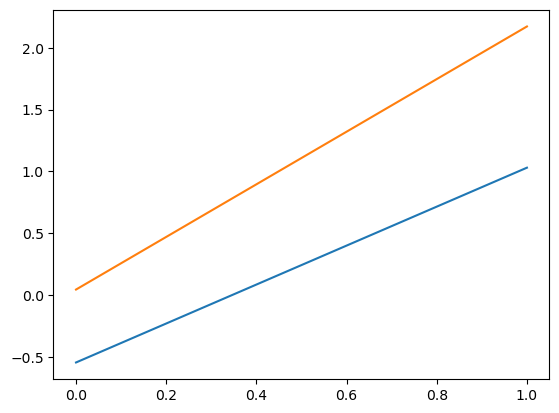

In [27]:
ft = 3
case =1999
plt.plot(models_dict_X['study3a_sampling_long_avg_T200_dt100_X_subsample_avg']['conditionals'][case,:,ft])
plt.plot(models_dict_X['study2b_sampling_long_T200_dt100_X']['conditionals'][case,:,ft])

# models_dict_X['study3a_sampling_long_avg_T200_dt100_X_subsample_avg'].keys()

## Run scatter plots and histograms for all experiments

In [14]:
keys =  list(models_dict_v2.keys())


# Usage
for key in [keys[0],keys[1],keys[5],keys[10],keys[15],keys[-1]]:
    print (f"Computing coverage for model: {key}")
    param_labels = ['rho', 'sigma', 'beta']

    empirical_coverage, credible_levels = compute_coverage_analysis(
        models_dict, key, credible_levels=[0.5, 0.68, 0.90, 0.95]
    )

    fig = plot_calibration(empirical_coverage, credible_levels, param_labels)
    # plt.savefig(f'./plots/calibration_plot_{key}.png', dpi=300, bbox_inches='tight')
plt.show()

# # Print numerical results
# print("Empirical Coverage Results:")
# for level in credible_levels:
#     print(f"\n{level*100:.0f}% Credible Interval:")
#     for i, label in enumerate(param_labels):
#         print(f"  {label}: {empirical_coverage[level][i]:.3f}")

NameError: name 'models_dict_v2' is not defined

## Parameter Recovery for some of the experimensts- R2 seems too large for some cases when we compare to what we see visually!

From this plot we can identify cases where the nflow is doing bad and then investigate why it is doing bad on those cases

Computing parameter recovery for model: study3_summaries_T5_dt1_Y_avg


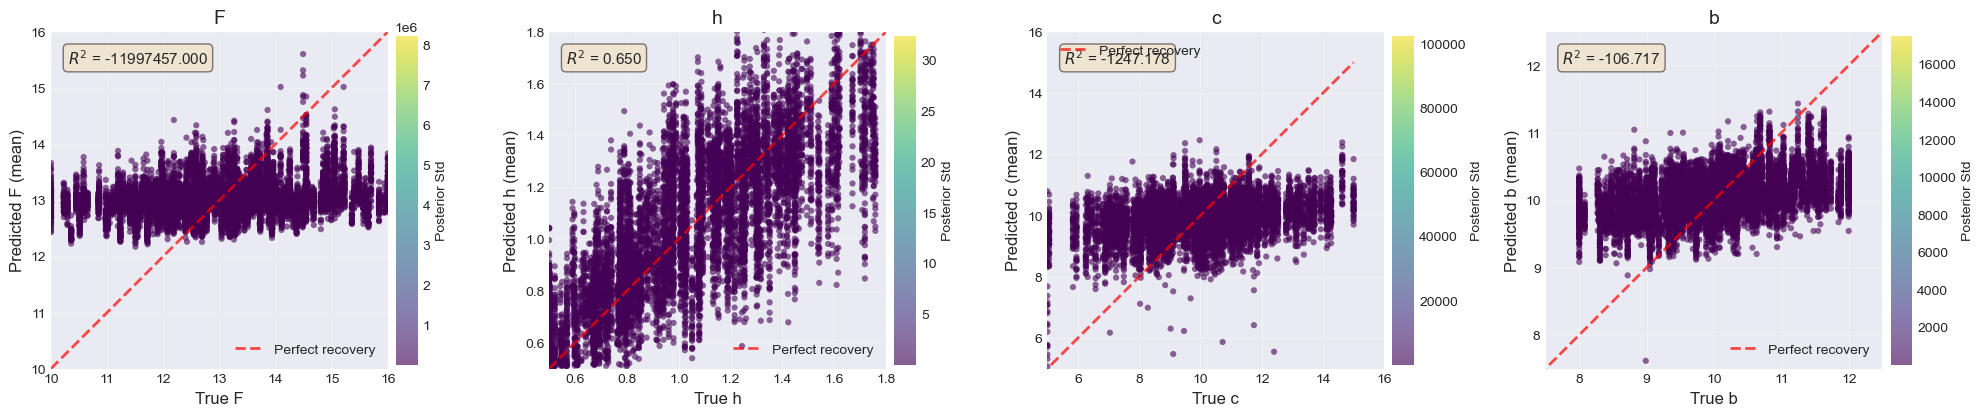

Computing parameter recovery for model: study3_summaries_T10_dt1_Y_avg


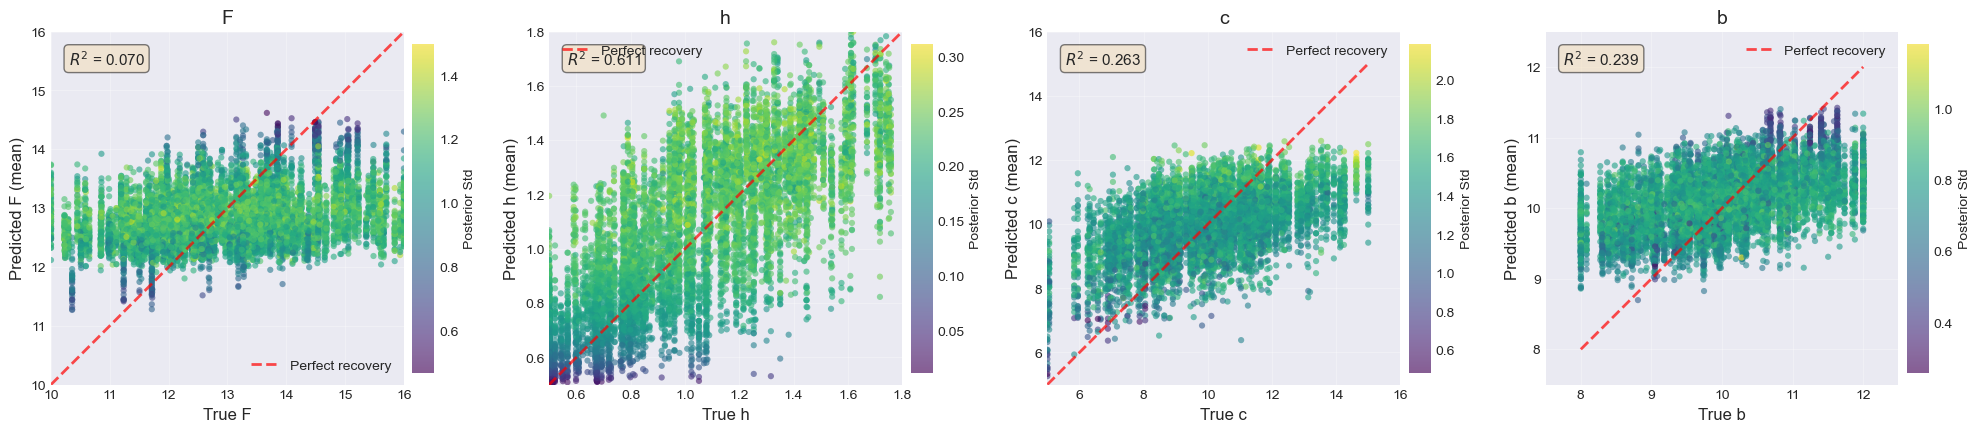

Computing parameter recovery for model: study3_summaries_T50_dt1_Y_avg


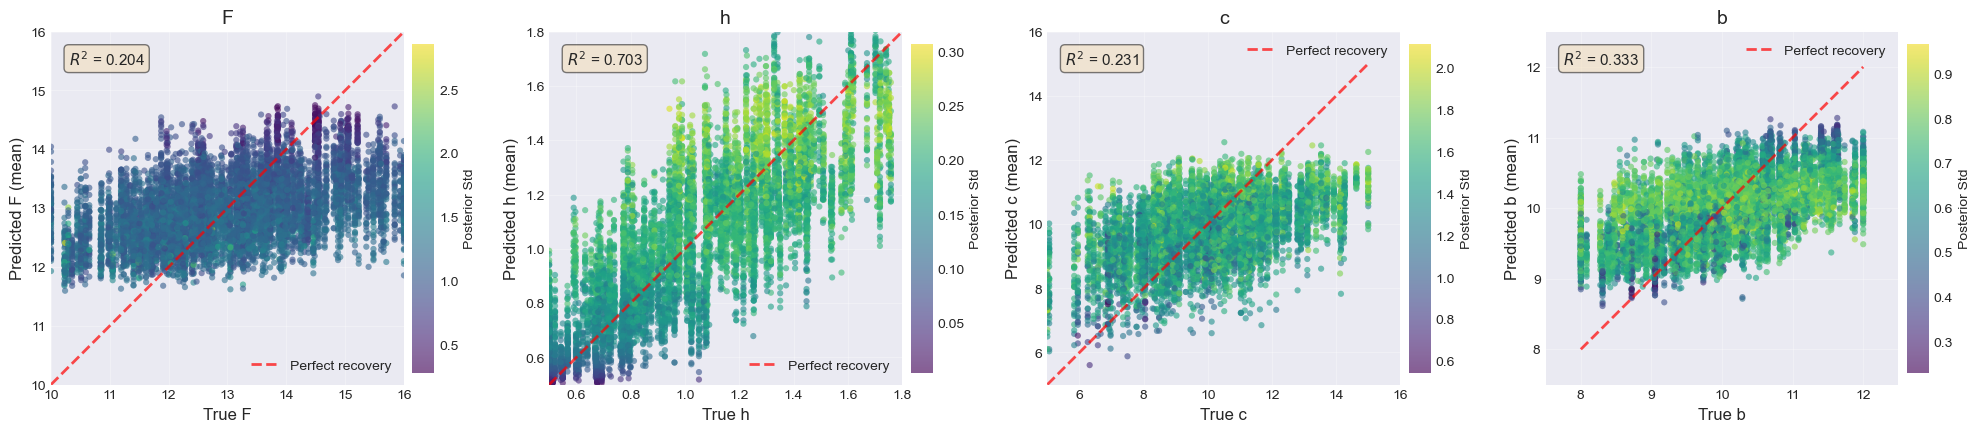

Computing parameter recovery for model: study3_summaries_T100_dt1_Y_avg


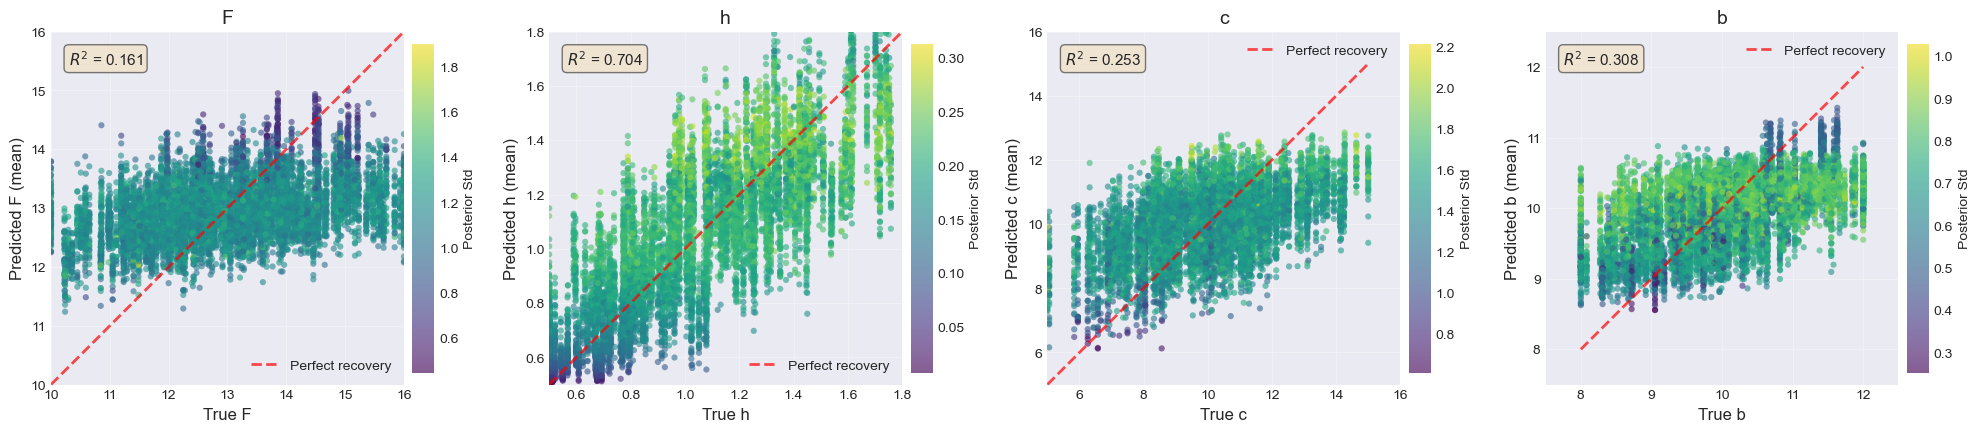

Computing parameter recovery for model: study3_summaries_T200_dt1_Y_avg


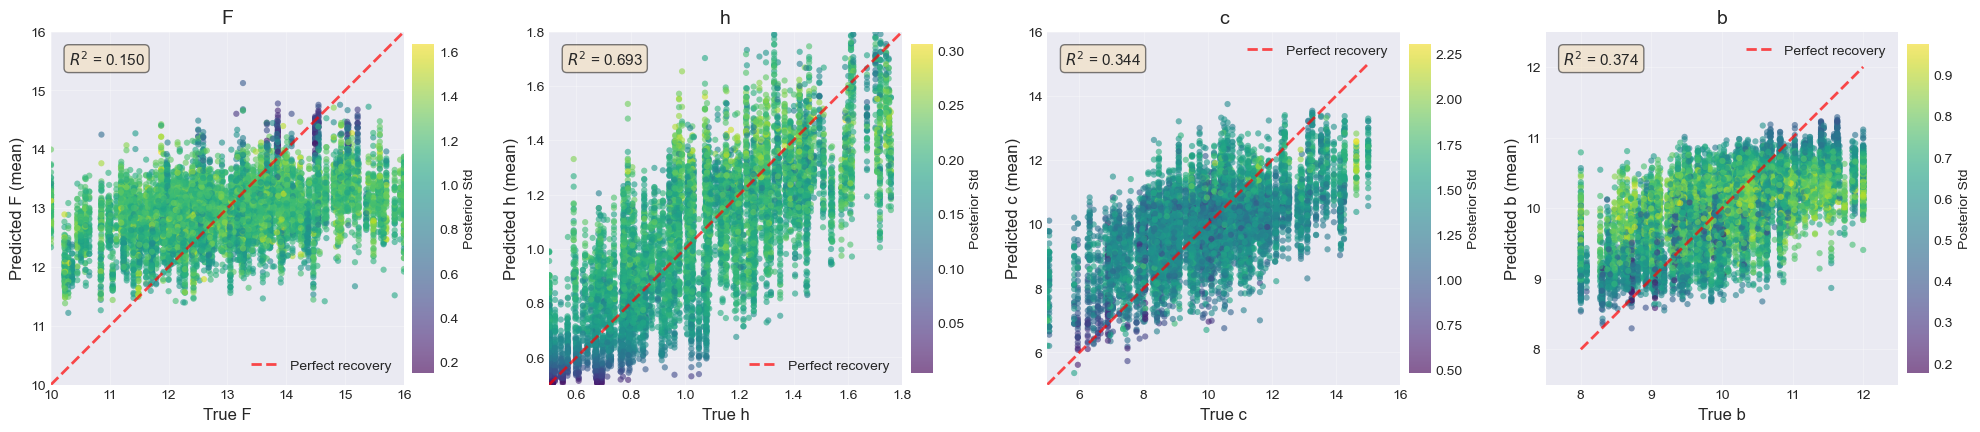

In [24]:
from util_plots import plot_parameter_recovery

# Usage
for key in keys_Y[0:16]:
    print (f"Computing parameter recovery for model: {key}")
    param_labels = ['F', 'h', 'c','b']

    fig = plot_parameter_recovery(models_dict_Y, key, param_labels, range = [[10,16],[0.5,1.8],[5.0,16],[7.5,12.5]])
    # plt.savefig(f'./plots/lstm_parameter_recovery_{key}.png', dpi=300, bbox_inches='tight')
    plt.show()



In [26]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from pathlib import Path
import seaborn as sns

# Set style for better-looking plots
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Define a beautiful color palette
COLORS = {
    'posterior': '#3498db',  # Bright blue
    'true': '#e74c3c',       # Vibrant red
    'identity': '#2c3e50',   # Dark blue-gray
    'grid': '#ecf0f1'        # Light gray
}

def analyze_derived_parameter(ax_hist, ax_scatter, true_values, samples, 
                              param_name, xlim=None, text_pos=None):
    """
    Analyze and plot a single derived parameter with enhanced visuals.
    
    Parameters:
    -----------
    ax_hist : matplotlib axis
        Axis for histogram plot
    ax_scatter : matplotlib axis
        Axis for scatter plot
    true_values : array
        True parameter values
    samples : array
        Posterior samples (n_samples x n_posterior)
    param_name : str
        Name of parameter for labels
    xlim : tuple, optional
        X-axis limits for plots
    text_pos : tuple, optional
        Position for R² text annotation
    """
    # Calculate posterior means
    predicted = np.mean(samples, axis=1)
    
    # Determine optimal number of bins using Freedman-Diaconis rule
    def freedman_diaconis_bins(data):
        q75, q25 = np.percentile(data, [75, 25])
        iqr = q75 - q25
        bin_width = 2 * iqr * len(data) ** (-1/3)
        if bin_width > 0:
            bins = int((data.max() - data.min()) / bin_width)
            return max(20, min(bins, 60))  # Constrain between 20 and 60
        return 40
    
    n_bins = freedman_diaconis_bins(np.concatenate([true_values, predicted]))
    
    # Histogram comparison with enhanced styling
    ax_hist.hist(predicted, bins=n_bins, density=True, alpha=0.7, 
                 label='Posterior Mean', color=COLORS['posterior'], 
                 edgecolor='white', linewidth=1.2)
    ax_hist.hist(true_values, bins=n_bins, density=True, alpha=0.7, 
                 label='True Values', color=COLORS['true'], 
                 edgecolor='white', linewidth=1.2)
    
    ax_hist.set_xlabel(param_name, fontsize=14, fontweight='bold')
    ax_hist.set_ylabel('Density', fontsize=14, fontweight='bold')
    ax_hist.legend(fontsize=11, frameon=True, shadow=True, fancybox=True)
    ax_hist.grid(True, alpha=0.3, linestyle='--', linewidth=0.8)
    ax_hist.tick_params(axis='both', which='major', labelsize=12, width=1.5, length=6)
    ax_hist.tick_params(axis='both', which='minor', labelsize=10, width=1, length=4)
    
    if xlim:
        ax_hist.set_xlim(xlim)
    
    # Add subtle background
    ax_hist.set_facecolor('#fafafa')
    
    # Scatter plot with enhanced styling
    ax_scatter.scatter(true_values, predicted, alpha=0.6, s=50, 
                      color=COLORS['posterior'], edgecolors='white', 
                      linewidth=0.5, zorder=2)
    
    # Dynamic identity line based on data range
    if xlim:
        line_range = xlim
    else:
        all_values = np.concatenate([true_values, predicted])
        margin = (all_values.max() - all_values.min()) * 0.05
        line_range = [all_values.min() - margin, all_values.max() + margin]
    
    ax_scatter.plot(line_range, line_range, color=COLORS['identity'], 
                   linestyle='--', linewidth=2.5, label='Perfect Prediction',
                   alpha=0.8, zorder=1)
    
    ax_scatter.set_xlabel(f'True {param_name}', fontsize=14, fontweight='bold')
    ax_scatter.set_ylabel(f'Predicted {param_name}', fontsize=14, fontweight='bold')
    ax_scatter.set_aspect('equal', adjustable='box')
    ax_scatter.grid(True, alpha=0.3, linestyle='--', linewidth=0.8)
    ax_scatter.tick_params(axis='both', which='major', labelsize=12, width=1.5, length=6)
    ax_scatter.tick_params(axis='both', which='minor', labelsize=10, width=1, length=4)
    ax_scatter.legend(fontsize=11, frameon=True, shadow=True, fancybox=True, loc='lower right')
    
    if xlim:
        ax_scatter.set_xlim(xlim)
        ax_scatter.set_ylim(xlim)
    
    # Add subtle background
    ax_scatter.set_facecolor('#fafafa')
    
    # Calculate and display R²
    r2 = r2_score(true_values, predicted)
    
    # Auto-position text if not specified
    if text_pos is None:
        x_range = ax_scatter.get_xlim()
        y_range = ax_scatter.get_ylim()
        text_pos = (x_range[0] + 0.05 * (x_range[1] - x_range[0]),
                   y_range[1] - 0.12 * (y_range[1] - y_range[0]))
    
    # Enhanced text box with better styling
    bbox_props = dict(boxstyle='round,pad=0.6', facecolor='white', 
                     edgecolor=COLORS['posterior'], linewidth=2, alpha=0.95)
    ax_scatter.text(text_pos[0], text_pos[1], f'$R^2 = {r2:.3f}$', 
                   fontsize=13, fontweight='bold', bbox=bbox_props, zorder=3)
    
    return r2


def plot_parameter_recovery(models_dict, key, output_dir='plots'):
    """
    Create comprehensive parameter recovery plots for derived parameters.
    
    Parameters:
    -----------
    models_dict : dict
        Dictionary containing model results
    key : str
        Key to access specific model results
    output_dir : str
        Directory to save plots
    """
    # Create output directory
    Path(output_dir).mkdir(parents=True, exist_ok=True)
    
    # Extract parameters
    params_true = models_dict[key]['params_true']
    params_gen = models_dict[key]['params_generated']
    
    # Calculate derived parameters: h*c/b
    hc_b_true = params_true[:, 1] * params_true[:, 2] / params_true[:, 3]
    hc_b_samples = (params_gen[:, :, 1] * params_gen[:, :, 2] / 
                    params_gen[:, :, 3])
    
    # Calculate derived parameters: c*b
    cb_true = params_true[:, 2] * params_true[:, 3]
    cb_samples = params_gen[:, :, 2] * params_gen[:, :, 3]
    
    # Create figure with enhanced styling
    fig = plt.figure(figsize=(14, 11))
    gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.3, 
                         left=0.08, right=0.95, top=0.92, bottom=0.08)
    
    axes = [[fig.add_subplot(gs[i, j]) for j in range(2)] for i in range(2)]
    
    # Main title with enhanced styling
    fig.suptitle(f'Derived Parameter Recovery: {key.replace("_", " ").title()}', 
                 fontsize=16, fontweight='bold', y=0.97,
                 bbox=dict(boxstyle='round,pad=0.8', facecolor='lightgray', 
                          edgecolor='gray', linewidth=2, alpha=0.8))
    
    # Analyze h*c/b
    print(f"\n{'='*70}")
    print(f"{'ANALYSIS':^70}")
    print(f"{'='*70}")
    print(f"Study: {key}")
    print(f"{'-'*70}")
    print(f"\n{'Derived Parameter: h·c/b':<30}")
    print(f"{'-'*70}")
    
    r2_hcb = analyze_derived_parameter(
        axes[0][0], axes[0][1], 
        hc_b_true, hc_b_samples,
        param_name='h·c/b',
        xlim=(0, 2.5),
        text_pos=(0.15, 2.25)
    )
    
    mae_hcb = np.mean(np.abs(hc_b_true - np.mean(hc_b_samples, 1)))
    rmse_hcb = np.sqrt(np.mean((hc_b_true - np.mean(hc_b_samples, 1))**2))
    
    print(f"  R² Score:              {r2_hcb:>8.4f}")
    print(f"  Mean Absolute Error:   {mae_hcb:>8.4f}")
    print(f"  Root Mean Squared Error: {rmse_hcb:>6.4f}")
    
    # Add subtitle for first row
    fig.text(0.5, 0.92, 'Parameter: h·c/b', ha='center', fontsize=13, 
             fontweight='bold', style='italic')
    
    # Analyze c*b
    print(f"\n{'Derived Parameter: c·b':<30}")
    print(f"{'-'*70}")
    
    r2_cb = analyze_derived_parameter(
        axes[1][0], axes[1][1],
        cb_true, cb_samples,
        param_name='c·b',
        xlim=None  # Auto-scale
    )
    
    mae_cb = np.mean(np.abs(cb_true - np.mean(cb_samples, 1)))
    rmse_cb = np.sqrt(np.mean((cb_true - np.mean(cb_samples, 1))**2))
    
    print(f"  R² Score:              {r2_cb:>8.4f}")
    print(f"  Mean Absolute Error:   {mae_cb:>8.4f}")
    print(f"  Root Mean Squared Error: {rmse_cb:>6.4f}")
    print(f"{'='*70}\n")
    
    # Add subtitle for second row
    fig.text(0.5, 0.47, 'Parameter: c·b', ha='center', fontsize=13, 
             fontweight='bold', style='italic')
    
    # Save figure in multiple formats
    safe_key = key.replace('/', '_').replace(' ', '_')
    
    # High-resolution PNG
    output_path = Path(output_dir) / f'lstm_parameter_recovery_{safe_key}.png'
    plt.savefig(output_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"📊 Plot saved to: {output_path}")
    
    # Vector PDF for publications
    pdf_path = Path(output_dir) / f'lstm_parameter_recovery_{safe_key}.pdf'
    plt.savefig(pdf_path, bbox_inches='tight', facecolor='white')
    print(f"📄 PDF saved to: {pdf_path}")
    
    # Optional: SVG for web/presentations
    svg_path = Path(output_dir) / f'lstm_parameter_recovery_{safe_key}.svg'
    plt.savefig(svg_path, bbox_inches='tight', facecolor='white')
    print(f"🎨 SVG saved to: {svg_path}")
    
    plt.show()
    
    return fig


# ============================================================
# Main execution
# ============================================================

# Define keys to analyze
keys_to_analyze = [
    'study3_summaries_T50_dt1_X_avg',
    'study1_temporal_extent_T50_dt1_X'
]




                               ANALYSIS                               
Study: study3_summaries_T200_dt1_X_avg
----------------------------------------------------------------------

Derived Parameter: h·c/b      
----------------------------------------------------------------------
  R² Score:                0.3225
  Mean Absolute Error:     0.2896
  Root Mean Squared Error: 0.3615

Derived Parameter: c·b        
----------------------------------------------------------------------
  R² Score:               -0.0016
  Mean Absolute Error:    16.7242
  Root Mean Squared Error: 20.3869

📊 Plot saved to: plots/parameter_recovery/lstm_parameter_recovery_study3_summaries_T200_dt1_X_avg.png
📄 PDF saved to: plots/parameter_recovery/lstm_parameter_recovery_study3_summaries_T200_dt1_X_avg.pdf
🎨 SVG saved to: plots/parameter_recovery/lstm_parameter_recovery_study3_summaries_T200_dt1_X_avg.svg


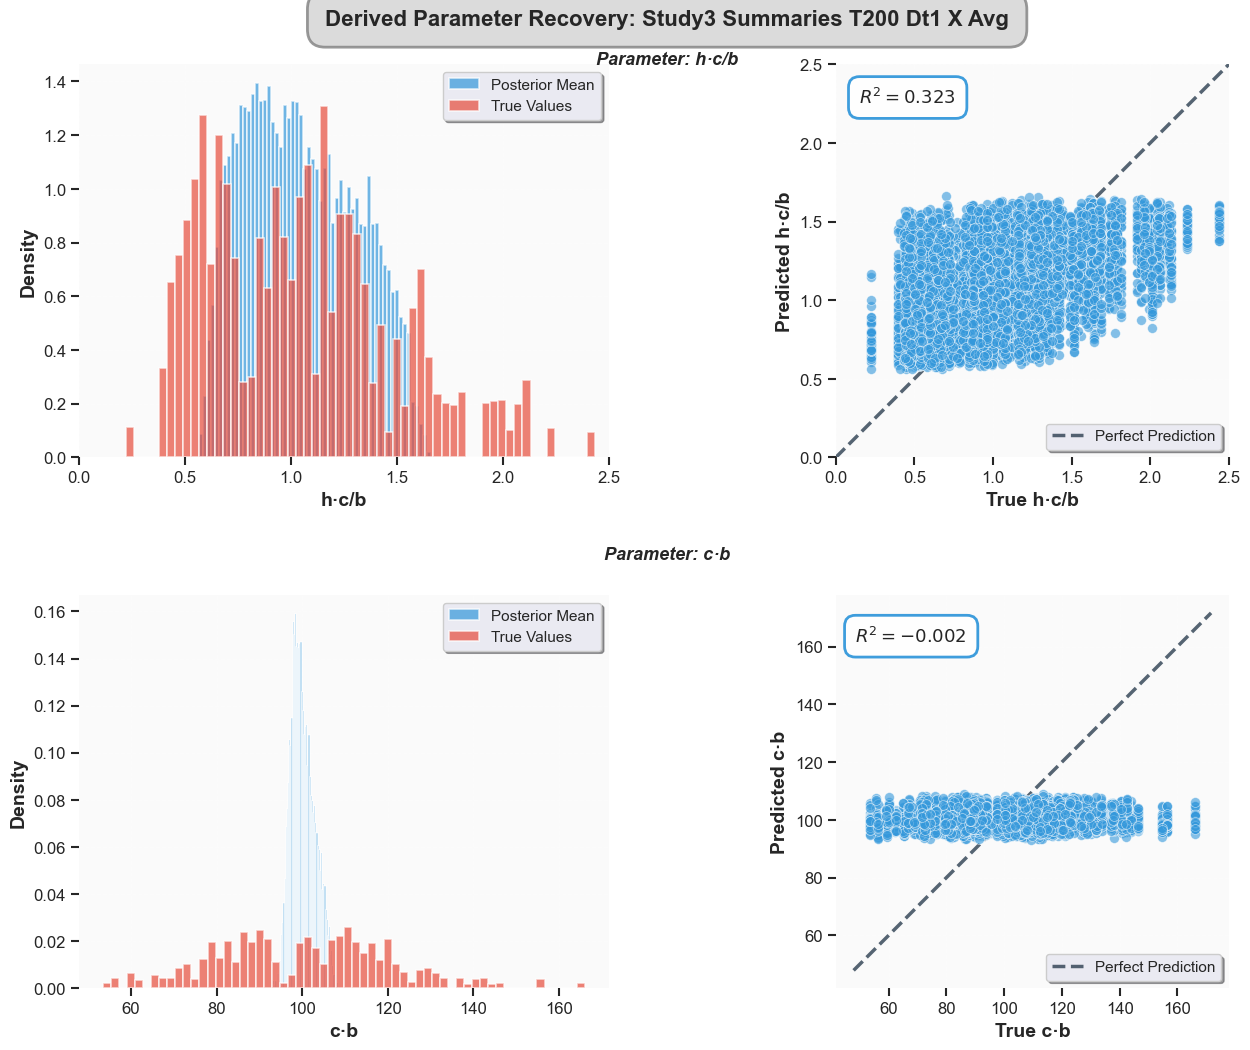


                               ANALYSIS                               
Study: study3_summaries_T1_dt1_X_avg
----------------------------------------------------------------------

Derived Parameter: h·c/b      
----------------------------------------------------------------------
  R² Score:              -54353936412311552.0000
  Mean Absolute Error:   4103181.5000
  Root Mean Squared Error: 102397072.0000

Derived Parameter: c·b        
----------------------------------------------------------------------
  R² Score:              -1139360137216.0000
  Mean Absolute Error:   7620734.5000
  Root Mean Squared Error: 21744072.0000

📊 Plot saved to: plots/parameter_recovery/lstm_parameter_recovery_study3_summaries_T1_dt1_X_avg.png
📄 PDF saved to: plots/parameter_recovery/lstm_parameter_recovery_study3_summaries_T1_dt1_X_avg.pdf
🎨 SVG saved to: plots/parameter_recovery/lstm_parameter_recovery_study3_summaries_T1_dt1_X_avg.svg


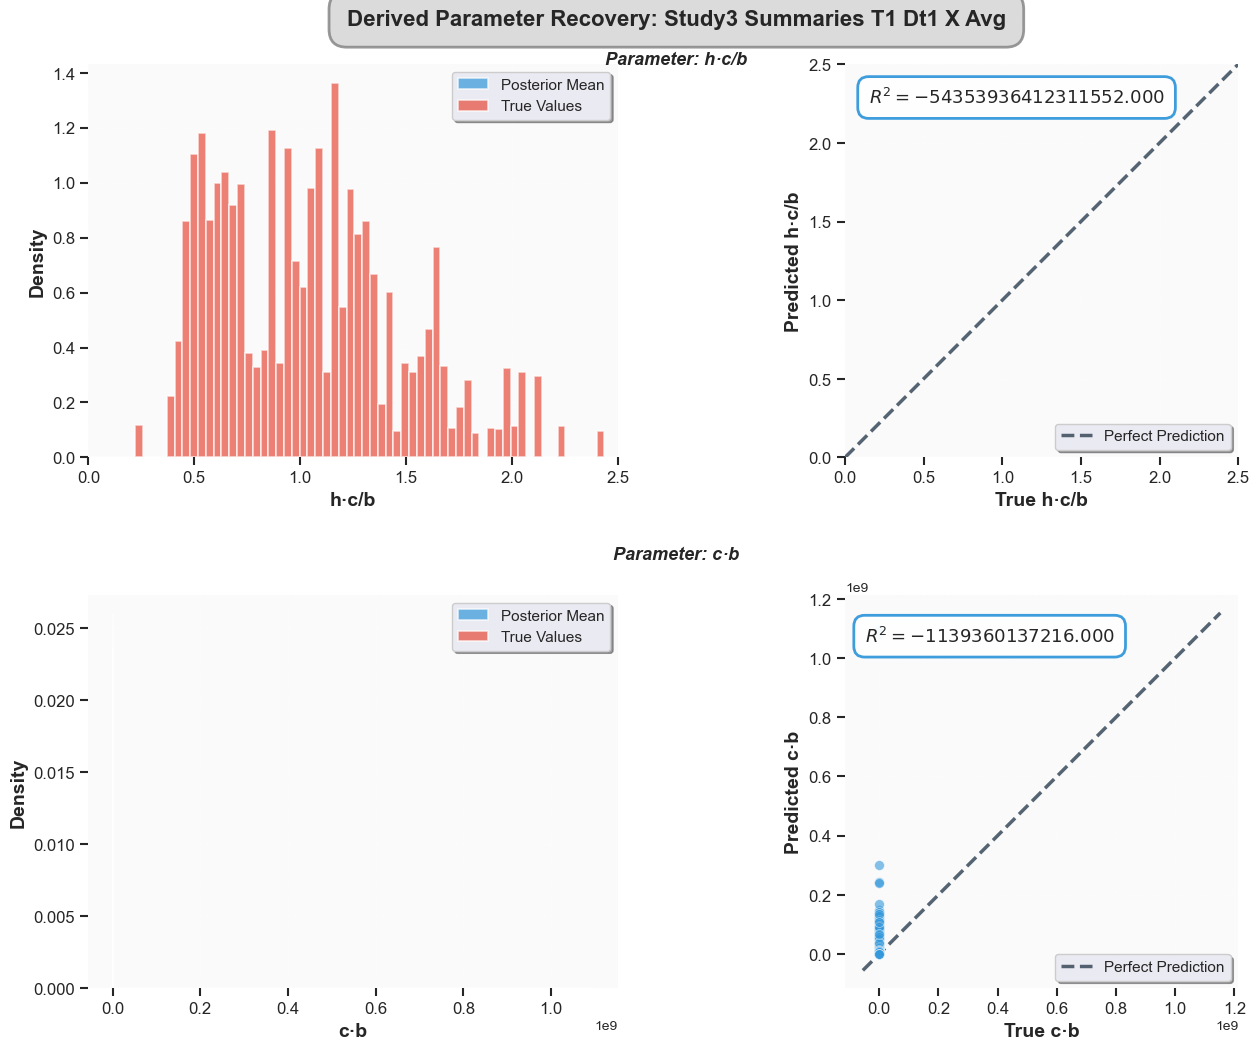

In [30]:
# Analyze each study
for key in keys_X[4:6]:
    if key in models_dict_X:
        plot_parameter_recovery(models_dict_X, key, output_dir='plots/parameter_recovery')
    else:
        print(f"⚠️  Warning: Key '{key}' not found in models_dict")

In [18]:
def identify_modes_and_compute_metrics(theta_true, theta_pred, n_modes=2, param_idx=None, param_name=None):
    """
    Identify modes in the true parameter distribution and compute R² per mode
    
    Args:
        theta_true: (N, 3) true parameters
        theta_pred: (N, 3) predicted parameters
        n_modes: number of modes to identify (default 2 for bimodal)
        param_idx: which parameter to analyze (0=rho, 1=sigma, 2=beta)
        param_name: name of parameter for printing
    
    Returns:
        Dictionary with per-mode metrics
    """
    from sklearn.mixture import GaussianMixture
    from sklearn.metrics import mean_squared_error, r2_score
    
    if param_idx is None:
        print("Error: Must specify param_idx")
        return None
    
    # Extract parameter values
    true_vals = theta_true[:, param_idx].reshape(-1, 1)
    pred_vals = theta_pred[:, param_idx]
    
    # Fit GMM to identify modes in TRUE parameters
    gmm = GaussianMixture(n_components=n_modes, random_state=42)
    mode_labels = gmm.fit_predict(true_vals)
    
    print(f"\n{'='*60}")
    print(f"Analysis for {param_name}: Identified {n_modes} modes")
    print(f"{'='*60}")
    
    mode_metrics = {}
    
    for mode in range(n_modes):
        mask = mode_labels == mode
        n_samples = mask.sum()
        
        if n_samples < 10:
            print(f"  Mode {mode}: Too few samples ({n_samples}), skipping")
            continue
        
        # Get data for this mode
        true_mode = theta_true[mask, param_idx]
        pred_mode = theta_pred[mask, param_idx]
        
        # Compute metrics
        r2 = r2_score(true_mode, pred_mode)
        rmse = np.sqrt(mean_squared_error(true_mode, pred_mode))
        mae = np.abs(true_mode - pred_mode).mean()
        bias = (pred_mode - true_mode).mean()
        
        # Residual analysis
        residuals = pred_mode - true_mode
        from scipy.stats import linregress
        slope, intercept, r_val, p_val, std_err = linregress(true_mode, residuals)
        
        # Store metrics
        mode_metrics[f'mode_{mode}'] = {
            'n_samples': int(n_samples),
            'true_mean': float(true_mode.mean()),
            'true_std': float(true_mode.std()),
            'true_range': (float(true_mode.min()), float(true_mode.max())),
            'r2': float(r2),
            'rmse': float(rmse),
            'mae': float(mae),
            'bias': float(bias),
            'residual_slope': float(slope),
            'residual_pvalue': float(p_val)
        }
        
        # Print results
        print(f"\n  Mode {mode}:")
        print(f"    Samples: {n_samples}")
        print(f"    True value range: [{true_mode.min():.3f}, {true_mode.max():.3f}]")
        print(f"    True mean ± std: {true_mode.mean():.3f} ± {true_mode.std():.3f}")
        print(f"    R²: {r2:.4f}")
        print(f"    RMSE: {rmse:.4f}")
        print(f"    MAE: {mae:.4f}")
        print(f"    Bias: {bias:+.4f}")
        print(f"    Residual slope: {slope:.4f} (p={p_val:.4e})")
        
        if p_val < 0.05:
            print(f"    ⚠️  Systematic bias detected!")
        else:
            print(f"    ✓ No systematic bias")
    
    return mode_metrics, mode_labels


def compute_metrics_with_mode_analysis(theta_true, theta_pred, n_modes=2):
    """
    Enhanced version that includes per-mode analysis for all parameters
    All metrics are truncated to 2 decimal places (not rounded)
    """
    from sklearn.metrics import mean_squared_error, mean_absolute_error
    import math
    
    def truncate_to_2_decimals(value):
        """Truncate to 2 decimal places without rounding"""
        return math.floor(value * 100) / 100
    
    metrics = {}
    params = ['rho', 'sigma', 'beta']
    
    print("\n" + "="*80)
    print("OVERALL METRICS")
    print("="*80)
    
    for i, param in enumerate(params):
        residuals = theta_pred[:, i] - theta_true[:, i]
        
        # Basic accuracy - truncate to 2 decimals
        metrics[f'{param}_rmse'] = truncate_to_2_decimals(
            np.sqrt(mean_squared_error(theta_true[:, i], theta_pred[:, i]))
        )
        metrics[f'{param}_mae'] = truncate_to_2_decimals(
            mean_absolute_error(theta_true[:, i], theta_pred[:, i])
        )
        
        # Bias - truncate to 2 decimals
        metrics[f'{param}_bias'] = truncate_to_2_decimals(residuals.mean())
        
        # Correlation (what R² measures) - truncate to 2 decimals
        metrics[f'{param}_r2'] = truncate_to_2_decimals(
            np.corrcoef(theta_true[:, i], theta_pred[:, i])[0,1]**2
        )
        
        # Systematic error detection
        from scipy.stats import linregress
        slope, intercept, r_value, p_value, std_err = linregress(theta_true[:, i], residuals)
        
        metrics[f'{param}_residual_slope'] = truncate_to_2_decimals(slope)
        metrics[f'{param}_residual_slope_pvalue'] = p_value  # Keep full precision for p-value
        
        # Per-mode analysis
        print(f"\n" + "="*80)
        print(f"PER-MODE ANALYSIS: {param.upper()}")
        print("="*80)
        
        mode_metrics, mode_labels = identify_modes_and_compute_metrics(
            theta_true, theta_pred, 
            n_modes=n_modes, 
            param_idx=i, 
            param_name=param
        )
        
        # Truncate mode metrics to 2 decimals
        if mode_metrics:
            for mode_key, mode_data in mode_metrics.items():
                mode_data['r2'] = truncate_to_2_decimals(mode_data['r2'])
                mode_data['rmse'] = truncate_to_2_decimals(mode_data['rmse'])
                mode_data['mae'] = truncate_to_2_decimals(mode_data['mae'])
                mode_data['bias'] = truncate_to_2_decimals(mode_data['bias'])
                mode_data['residual_slope'] = truncate_to_2_decimals(mode_data['residual_slope'])
                mode_data['true_mean'] = truncate_to_2_decimals(mode_data['true_mean'])
                mode_data['true_std'] = truncate_to_2_decimals(mode_data['true_std'])
                # Truncate range tuple
                mode_data['true_range'] = (
                    truncate_to_2_decimals(mode_data['true_range'][0]),
                    truncate_to_2_decimals(mode_data['true_range'][1])
                )
            
            # Calculate and store mean R² across all modes
            r2_values = [mode_data['r2'] for mode_data in mode_metrics.values()]
            mean_mode_r2 = truncate_to_2_decimals(np.mean(r2_values))
            metrics[f'{param}_mean_mode_r2'] = mean_mode_r2
            
            print(f"\n  Mean R² across all modes: {mean_mode_r2:.2f}")
        
        metrics[f'{param}_mode_metrics'] = mode_metrics
        metrics[f'{param}_mode_labels'] = mode_labels
    
    # Print summary table
    print("\n" + "="*80)
    print("SUMMARY TABLE: Overall vs Per-Mode Metrics")
    print("="*80)
    print(f"\n{'Parameter':<10} {'Scope':<15} {'R²':<8} {'RMSE':<8} {'MAE':<8} {'Bias':<10} {'Sys.Bias?'}")
    print("-" * 85)
    
    for param in ['rho', 'sigma', 'beta']:
        # Overall metrics
        r2 = metrics[f'{param}_r2']
        rmse = metrics[f'{param}_rmse']
        mae = metrics[f'{param}_mae']
        bias = metrics[f'{param}_bias']
        p_val = metrics[f'{param}_residual_slope_pvalue']
        sys_bias = "YES ⚠️" if p_val < 0.05 else "No ✓"
        
        print(f"{param:<10} {'Overall':<15} {r2:<8.2f} {rmse:<8.2f} {mae:<8.2f} {bias:<+10.2f} {sys_bias}")
        
        # Per-mode metrics
        if f'{param}_mode_metrics' in metrics:
            for mode_key, mode_data in metrics[f'{param}_mode_metrics'].items():
                mode_num = mode_key.split('_')[1]
                scope = f"  Mode {mode_num}"
                
                r2_mode = mode_data['r2']
                rmse_mode = mode_data['rmse']
                mae_mode = mode_data['mae']
                bias_mode = mode_data['bias']
                p_val_mode = mode_data['residual_pvalue']
                sys_bias_mode = "YES ⚠️" if p_val_mode < 0.05 else "No ✓"
                
                print(f"{'':<10} {scope:<15} {r2_mode:<8.2f} {rmse_mode:<8.2f} {mae_mode:<8.2f} {bias_mode:<+10.2f} {sys_bias_mode}")
            
            # Print mean mode R²
            if f'{param}_mean_mode_r2' in metrics:
                mean_r2 = metrics[f'{param}_mean_mode_r2']
                print(f"{'':<10} {'  Mean Mode R²':<15} {mean_r2:<8.2f}")
        
        print("-" * 85)
    
    return metrics


def plot_mode_separated_recovery(theta_true, theta_pred, posterior_samples, metrics, key, save_path='./results/plots'):
    """
    Create recovery plots with modes highlighted in different colors
    Shows only one row with recovery plots
    R² displayed is the mean of all mode R² values (from metrics dict)
    Color represents posterior standard deviation
    
    Args:
        theta_true: (N_test, 3) true parameters
        theta_pred: (N_test, 3) predicted parameters (posterior mean)
        posterior_samples: (N_test, N_samples, 3) posterior samples
        metrics: Dictionary with computed metrics
        key: Experiment key name
        save_path: Path to save plots
    """
    import os
    import math
    import matplotlib.pyplot as plt
    import matplotlib.cm as cm
    from matplotlib.colors import Normalize
    
    os.makedirs(save_path, exist_ok=True)
    
    params = ['rho', 'sigma', 'beta']
    params_names = ['ρ', 'σ', 'β']
    
    # Compute posterior standard deviation for each parameter
    posterior_std = posterior_samples.std(axis=1)  # (N_test, 3)
    
    # Single row with 3 subplots
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    for i, param in enumerate(params):
        ax = axes[i]
        
        if f'{param}_mode_labels' in metrics:
            mode_labels = metrics[f'{param}_mode_labels']
            mode_metrics = metrics[f'{param}_mode_metrics']
            
            # Get mean R² from metrics dict (already computed and truncated)
            mean_r2 = metrics[f'{param}_mean_mode_r2']
            
            # Get posterior std for this parameter
            param_posterior_std = posterior_std[:, i]
            
            # Normalize for colormap
            norm = Normalize(vmin=param_posterior_std.min(), 
                           vmax=param_posterior_std.max())
            
            # Plot each mode in different marker style, colored by posterior std
            markers = ['o', 's', '^', 'D', 'v']  # Different markers for different modes
            
            for mode_idx, mode in enumerate(np.unique(mode_labels)):
                mask = mode_labels == mode
                
                if mode < len(mode_metrics):
                    mode_data = mode_metrics[f'mode_{mode}']
                    r2_mode = mode_data['r2']
                    n_samples = mode_data['n_samples']
                    label = f"Mode {mode} (R²={r2_mode:.2f}, n={n_samples})"
                else:
                    label = f"Mode {mode}"
                
                # Scatter plot colored by posterior std
                scatter = ax.scatter(
                    theta_true[mask, i], 
                    theta_pred[mask, i],
                    c=param_posterior_std[mask],
                    cmap='viridis',
                    norm=norm,
                    marker=markers[mode_idx % len(markers)],
                    alpha=0.7,
                    s=50,
                    edgecolors='black',
                    linewidths=0.5,
                    label=label
                )
            
            # Perfect recovery line
            min_val = theta_true[:, i].min()
            max_val = theta_true[:, i].max()
            ax.plot([min_val, max_val], [min_val, max_val],
                   'r--', linewidth=2, label='Perfect recovery', zorder=10)
            
            ax.set_xlabel(f'True {params_names[i]}', fontsize=14)
            ax.set_ylabel(f'Predicted {params_names[i]}', fontsize=14)
            
            # Title shows mean R² of all modes (from metrics dict)
            ax.set_title(f'{params_names[i]}: Mean R² = {mean_r2:.2f}', 
                        fontsize=16, fontweight='bold')
            
            ax.legend(fontsize=10, loc='lower right')
            ax.grid(True, alpha=0.3)
            
            # Add colorbar
            cbar = plt.colorbar(scatter, ax=ax)
            cbar.set_label('Posterior Std Dev', fontsize=11)
    
    plt.tight_layout()
    plt.savefig(f'{save_path}/{key}_recovery_by_mode_v2.png', dpi=300, bbox_inches='tight')
    plt.close()
    print(f"✓ Saved mode-separated recovery plot: {key}_recovery_by_mode.png")


# ============================================================
# USAGE
# ============================================================

# Run enhanced analysis with mode detection
metrics = {}
for key in keys_X[:12]:
    metrics[key] = compute_metrics_with_mode_analysis(
        theta_true=models_dict_X[key]['params_true'],
        theta_pred=models_dict_X[key]['params_generated'].mean(axis=1),
        n_modes=2  # Change to 3 if you suspect 3 modes
    )

    # Create visualization - NOW INCLUDES posterior_samples
    plot_mode_separated_recovery(
        theta_true=models_dict_X[key]['params_true'],
        theta_pred=models_dict_X[key]['params_generated'].mean(axis=1),
        posterior_samples=models_dict_X[key]['params_generated'],
        metrics=metrics[key],
        key=key,
        save_path='./results/plots'
    )


OVERALL METRICS

PER-MODE ANALYSIS: RHO

Analysis for rho: Identified 2 modes

  Mode 0:
    Samples: 5273
    True value range: [10.000, 13.038]
    True mean ± std: 11.911 ± 0.727
    R²: -0.0358
    RMSE: 0.7395
    MAE: 0.6146
    Bias: +0.4469
    Residual slope: -0.4323 (p=0.0000e+00)
    ⚠️  Systematic bias detected!

  Mode 1:
    Samples: 4967
    True value range: [13.050, 16.000]
    True mean ± std: 14.148 ± 0.811
    R²: -0.3316
    RMSE: 0.9360
    MAE: 0.7212
    Bias: -0.5094
    Residual slope: -0.3977 (p=1.3498e-201)
    ⚠️  Systematic bias detected!

  Mean R² across all modes: -0.19

PER-MODE ANALYSIS: SIGMA

Analysis for sigma: Identified 2 modes

  Mode 0:
    Samples: 5230
    True value range: [1.012, 2.000]
    True mean ± std: 1.335 ± 0.236
    R²: -0.7848
    RMSE: 0.3154
    MAE: 0.2567
    Bias: -0.1930
    Residual slope: -0.7640 (p=0.0000e+00)
    ⚠️  Systematic bias detected!

  Mode 1:
    Samples: 5010
    True value range: [0.500, 1.010]
    True mea


===================================🔬 PARAMETER RECOVERY ANALYSIS ===================================

📊 Processing: study3_summaries_T50_dt1_X_avg

                                   Study3 Summaries T50 Dt1 X Avg                                   
+-------------+---------+---------+---------+------------+-----------------+-----------------+
|  Parameter  |      R² |     MAE |    RMSE |   MAPE (%) |  True Mean±Std  |  Pred Mean±Std  |
+=============+=========+=========+=========+============+=================+=================+
|      F      |  0.3308 |  0.9051 |  1.1101 |       7.05 |  12.996±1.357   |  12.999±0.444   |
+-------------+---------+---------+---------+------------+-----------------+-----------------+
|      h      |  0.1084 |  0.2802 |  0.3464 |      31.03 |   1.037±0.367   |   1.007±0.160   |
+-------------+---------+---------+---------+------------+-----------------+-----------------+
|      c      |  0.0352 |  1.4234 |  1.7949 |      15.21 |  10.004±1.827   |   9.985±

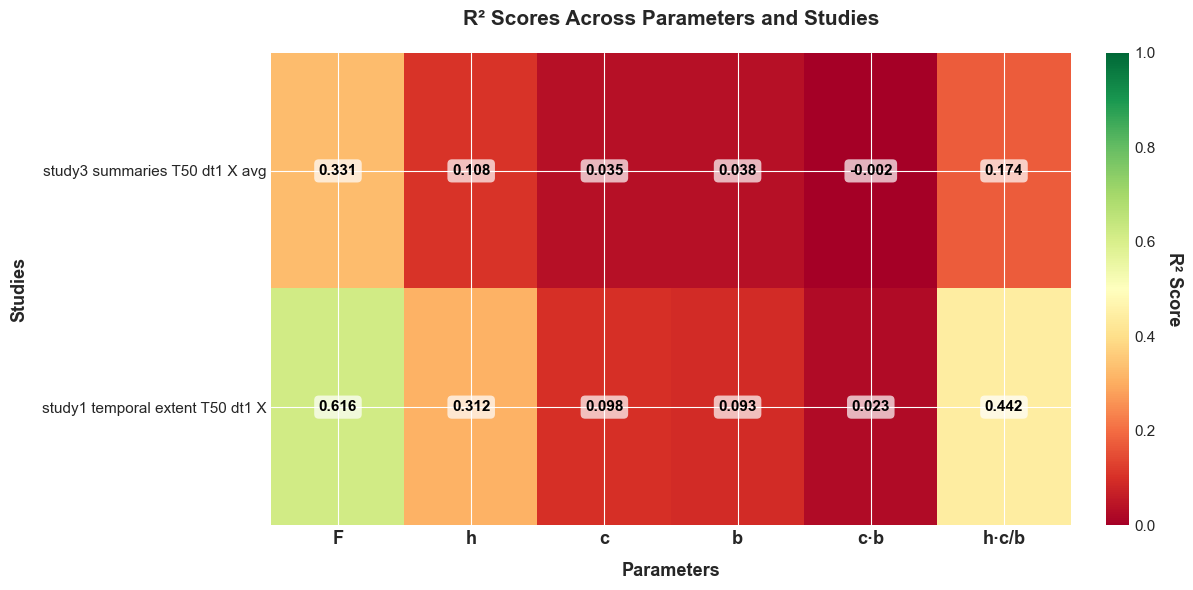

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from pathlib import Path
import pandas as pd
from tabulate import tabulate

def compute_parameter_metrics(models_dict, key):
    """
    Compute R², MAE, and RMSE for all parameters including derived ones.
    
    Parameters:
    -----------
    models_dict : dict
        Dictionary containing model results
    key : str
        Key to access specific model results
        
    Returns:
    --------
    dict : Dictionary containing metrics for each parameter
    """
    # Extract parameters
    params_true = models_dict[key]['params_true']
    params_gen = models_dict[key]['params_generated']
    
    # Calculate posterior means for base parameters
    params_predicted = np.mean(params_gen, axis=1)
    
    # Parameter names (assuming order: F, h, c, b)
    base_params = ['F', 'h', 'c', 'b']
    
    metrics = {}
    
    # Compute metrics for base parameters
    for i, param_name in enumerate(base_params):
        true_vals = params_true[:, i]
        pred_vals = params_predicted[:, i]
        
        r2 = r2_score(true_vals, pred_vals)
        mae = np.mean(np.abs(true_vals - pred_vals))
        rmse = np.sqrt(np.mean((true_vals - pred_vals)**2))
        
        # Calculate relative errors (as percentages)
        mape = np.mean(np.abs((true_vals - pred_vals) / (true_vals + 1e-10))) * 100
        
        metrics[param_name] = {
            'R²': r2,
            'MAE': mae,
            'RMSE': rmse,
            'MAPE (%)': mape,
            'True Mean': np.mean(true_vals),
            'True Std': np.std(true_vals),
            'Pred Mean': np.mean(pred_vals),
            'Pred Std': np.std(pred_vals)
        }
    
    # Compute metrics for derived parameter: c*b
    cb_true = params_true[:, 2] * params_true[:, 3]
    cb_samples = params_gen[:, :, 2] * params_gen[:, :, 3]
    cb_predicted = np.mean(cb_samples, axis=1)
    
    r2_cb = r2_score(cb_true, cb_predicted)
    mae_cb = np.mean(np.abs(cb_true - cb_predicted))
    rmse_cb = np.sqrt(np.mean((cb_true - cb_predicted)**2))
    mape_cb = np.mean(np.abs((cb_true - cb_predicted) / (cb_true + 1e-10))) * 100
    
    metrics['c·b'] = {
        'R²': r2_cb,
        'MAE': mae_cb,
        'RMSE': rmse_cb,
        'MAPE (%)': mape_cb,
        'True Mean': np.mean(cb_true),
        'True Std': np.std(cb_true),
        'Pred Mean': np.mean(cb_predicted),
        'Pred Std': np.std(cb_predicted)
    }
    
    # Compute metrics for derived parameter: h*c/b
    hcb_true = params_true[:, 1] * params_true[:, 2] / params_true[:, 3]
    hcb_samples = (params_gen[:, :, 1] * params_gen[:, :, 2] / 
                   params_gen[:, :, 3])
    hcb_predicted = np.mean(hcb_samples, axis=1)
    
    r2_hcb = r2_score(hcb_true, hcb_predicted)
    mae_hcb = np.mean(np.abs(hcb_true - hcb_predicted))
    rmse_hcb = np.sqrt(np.mean((hcb_true - hcb_predicted)**2))
    mape_hcb = np.mean(np.abs((hcb_true - hcb_predicted) / (hcb_true + 1e-10))) * 100
    
    metrics['h·c/b'] = {
        'R²': r2_hcb,
        'MAE': mae_hcb,
        'RMSE': rmse_hcb,
        'MAPE (%)': mape_hcb,
        'True Mean': np.mean(hcb_true),
        'True Std': np.std(hcb_true),
        'Pred Mean': np.mean(hcb_predicted),
        'Pred Std': np.std(hcb_predicted)
    }
    
    return metrics


def print_metrics_table(metrics_dict, study_name):
    """
    Print a formatted table of metrics for all parameters.
    
    Parameters:
    -----------
    metrics_dict : dict
        Dictionary containing metrics for each parameter
    study_name : str
        Name of the study for the title
    """
    # Prepare data for table
    table_data = []
    headers = ['Parameter', 'R²', 'MAE', 'RMSE', 'MAPE (%)', 
               'True Mean±Std', 'Pred Mean±Std']
    
    for param_name, metrics in metrics_dict.items():
        row = [
            param_name,
            f"{metrics['R²']:.4f}",
            f"{metrics['MAE']:.4f}",
            f"{metrics['RMSE']:.4f}",
            f"{metrics['MAPE (%)']:.2f}",
            f"{metrics['True Mean']:.3f}±{metrics['True Std']:.3f}",
            f"{metrics['Pred Mean']:.3f}±{metrics['Pred Std']:.3f}"
        ]
        table_data.append(row)
    
    # Print formatted table
    print(f"\n{'='*100}")
    print(f"{study_name.replace('_', ' ').title():^100}")
    print(f"{'='*100}")
    print(tabulate(table_data, headers=headers, tablefmt='grid', stralign='center'))
    print(f"{'='*100}\n")


def create_metrics_dataframe(all_metrics):
    """
    Create a pandas DataFrame from metrics of multiple studies.
    
    Parameters:
    -----------
    all_metrics : dict
        Dictionary with study names as keys and metrics dictionaries as values
        
    Returns:
    --------
    pd.DataFrame : DataFrame with all metrics
    """
    rows = []
    for study_name, metrics in all_metrics.items():
        for param_name, param_metrics in metrics.items():
            row = {
                'Study': study_name,
                'Parameter': param_name,
                'R²': param_metrics['R²'],
                'MAE': param_metrics['MAE'],
                'RMSE': param_metrics['RMSE'],
                'MAPE (%)': param_metrics['MAPE (%)'],
                'True Mean': param_metrics['True Mean'],
                'True Std': param_metrics['True Std'],
                'Pred Mean': param_metrics['Pred Mean'],
                'Pred Std': param_metrics['Pred Std']
            }
            rows.append(row)
    
    df = pd.DataFrame(rows)
    return df


def visualize_r2_comparison(all_metrics, output_dir='plots'):
    """
    Create a visual comparison of R² scores across parameters and studies.
    
    Parameters:
    -----------
    all_metrics : dict
        Dictionary with study names as keys and metrics dictionaries as values
    output_dir : str
        Directory to save the plot
    """
    # Prepare data
    studies = list(all_metrics.keys())
    params = ['F', 'h', 'c', 'b', 'c·b', 'h·c/b']
    
    # Create matrix of R² values
    r2_matrix = np.zeros((len(studies), len(params)))
    for i, study in enumerate(studies):
        for j, param in enumerate(params):
            if param in all_metrics[study]:
                r2_matrix[i, j] = all_metrics[study][param]['R²']
    
    # Create figure
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Create heatmap
    im = ax.imshow(r2_matrix, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)
    
    # Set ticks and labels
    ax.set_xticks(np.arange(len(params)))
    ax.set_yticks(np.arange(len(studies)))
    ax.set_xticklabels(params, fontsize=13, fontweight='bold')
    ax.set_yticklabels([s.replace('_', ' ') for s in studies], fontsize=11)
    
    # Rotate the tick labels for better readability
    plt.setp(ax.get_xticklabels(), rotation=0, ha="center")
    
    # Add colorbar
    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('R² Score', rotation=270, labelpad=20, fontsize=13, fontweight='bold')
    cbar.ax.tick_params(labelsize=11)
    
    # Add text annotations
    for i in range(len(studies)):
        for j in range(len(params)):
            text = ax.text(j, i, f'{r2_matrix[i, j]:.3f}',
                          ha="center", va="center", color="black",
                          fontsize=11, fontweight='bold',
                          bbox=dict(boxstyle='round,pad=0.3', 
                                  facecolor='white', alpha=0.7, edgecolor='none'))
    
    ax.set_title('R² Scores Across Parameters and Studies', 
                 fontsize=15, fontweight='bold', pad=20)
    ax.set_xlabel('Parameters', fontsize=13, fontweight='bold', labelpad=10)
    ax.set_ylabel('Studies', fontsize=13, fontweight='bold', labelpad=10)
    
    plt.tight_layout()
    
    # Save figure
    Path(output_dir).mkdir(parents=True, exist_ok=True)
    output_path = Path(output_dir) / 'r2_comparison_heatmap.png'
    plt.savefig(output_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"📊 R² comparison heatmap saved to: {output_path}")
    
    pdf_path = Path(output_dir) / 'r2_comparison_heatmap.pdf'
    plt.savefig(pdf_path, bbox_inches='tight', facecolor='white')
    print(f"📄 PDF saved to: {pdf_path}")
    
    plt.show()
    
    return fig


def save_metrics_to_csv(df, output_dir='results'):
    """
    Save metrics DataFrame to CSV file.
    
    Parameters:
    -----------
    df : pd.DataFrame
        DataFrame containing all metrics
    output_dir : str
        Directory to save the CSV file
    """
    Path(output_dir).mkdir(parents=True, exist_ok=True)
    output_path = Path(output_dir) / 'parameter_recovery_metrics.csv'
    df.to_csv(output_path, index=False)
    print(f"💾 Metrics saved to: {output_path}")


# ============================================================
# Main execution
# ============================================================

def analyze_all_studies(models_dict, keys_to_analyze, output_dir='plots/metrics'):
    """
    Complete analysis pipeline for all studies.
    
    Parameters:
    -----------
    models_dict : dict
        Dictionary containing all model results
    keys_to_analyze : list
        List of study keys to analyze
    output_dir : str
        Directory for output files
    """
    all_metrics = {}
    
    print("\n" + "🔬 PARAMETER RECOVERY ANALYSIS ".center(100, "="))
    
    # Compute metrics for each study
    for key in keys_to_analyze:
        if key in models_dict:
            print(f"\n📊 Processing: {key}")
            metrics = compute_parameter_metrics(models_dict, key)
            all_metrics[key] = metrics
            print_metrics_table(metrics, key)
        else:
            print(f"⚠️  Warning: Key '{key}' not found in models_dict")
    
    # Create summary DataFrame
    df = create_metrics_dataframe(all_metrics)
    
    # Print summary statistics
    print("\n" + "📈 SUMMARY STATISTICS ".center(100, "="))
    print("\nAverage R² by Parameter:")
    print("-" * 100)
    r2_summary = df.groupby('Parameter')['R²'].agg(['mean', 'std', 'min', 'max'])
    print(tabulate(r2_summary, headers=['Parameter', 'Mean R²', 'Std R²', 'Min R²', 'Max R²'], 
                   tablefmt='grid', floatfmt='.4f'))
    
    print("\n" + "="*100 + "\n")
    
    # Save results
    save_metrics_to_csv(df, output_dir=output_dir)
    
    # Create visualization
    visualize_r2_comparison(all_metrics, output_dir=output_dir)
    
    return all_metrics, df


# Example usage
keys_to_analyze = [
    'study3_summaries_T50_dt1_X_avg',
    'study1_temporal_extent_T50_dt1_X'
]

all_metrics, metrics_df = analyze_all_studies(models_dict_X, keys_to_analyze, 
                                              output_dir='plots/metrics')

# Optional: Access specific metrics
# print("\nAccess specific R² for study1, parameter F:")
# print(all_metrics['study1_temporal_extent_T50_dt1_X']['F']['R²'])

# Below is the code for corner plot


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from pathlib import Path

def compute_r2_for_parameters(models_dict, key):
    """
    Compute R² for base parameters (assuming order: F, h, c, b).
    
    Parameters:
    -----------
    models_dict : dict
        Dictionary containing model results
    key : str
        Key to access specific model results
        
    Returns:
    --------
    dict : Dictionary with R² values for each parameter
    """
    # Extract parameters
    params_true = models_dict[key]['params_true']
    params_gen = models_dict[key]['params_generated']
    
    # Calculate posterior means
    params_predicted = np.mean(params_gen, axis=1)
    
    # Compute R² for each parameter (assuming order: F, h, c, b)
    r2_values = {}
    param_names = ['ρ', 'σ', 'β', 'F']  # Adjust based on your parameter names
    # Or if your parameters are F, h, c, b:
    # param_names = ['F', 'h', 'c', 'b']
    
    for i, param_name in enumerate(param_names):
        if i < params_true.shape[1]:
            true_vals = params_true[:, i]
            pred_vals = params_predicted[:, i]
            r2_values[param_name] = r2_score(true_vals, pred_vals)
    
    return r2_values


def extract_experiment_params(key):
    """
    Extract T and dt from the key name.
    
    Parameters:
    -----------
    key : str
        Key name like 'study1_temporal_extent_T50_dt1_X'
        
    Returns:
    --------
    tuple : (T, dt) values
    """
    import re
    
    # Extract T value
    t_match = re.search(r'T(\d+)', key)
    T = int(t_match.group(1)) if t_match else None
    
    # Extract dt value
    dt_match = re.search(r'dt(\d+)', key)
    dt = int(dt_match.group(1)) if dt_match else None
    
    return T, dt


def create_r2_summary_table(models_dict, keys_to_analyze, experiment =None, output_dir='plots/tables'):
    """
    Create a text-based R² summary table matching the style in the image.
    
    Parameters:
    -----------
    models_dict : dict
        Dictionary containing all model results
    keys_to_analyze : list
        List of study keys to analyze
    output_dir : str
        Directory to save the figure
    """
    # Collect all R² values
    results = []
    
    for key in keys_to_analyze:
        if key in models_dict:
            T, dt = extract_experiment_params(key)
            r2_values = compute_r2_for_parameters(models_dict, key)
            
            results.append({
                'key': key,
                'T': T,
                'dt': dt,
                'r2_values': max(r2_values,0)  # Ensure non-negative R²
            })
        else:
            print(f"⚠️  Warning: Key '{key}' not found in models_dict")
    
    # Sort by T value
    results.sort(key=lambda x: x['T'] if x['T'] is not None else 0, reverse=True)
    
    # Create figure
    fig, ax = plt.subplots(figsize=(14, len(results) * 0.8 + 1))
    ax.axis('off')
    
    # Create text lines
    text_lines = []
    for result in results:
        T = result['T']
        dt = result['dt']
        r2_vals = result['r2_values']
        
        # Format R² values
        r2_strs = [f"$R^2_{{{param}}} = {r2:.2f}$" for param, r2 in r2_vals.items()]
        r2_text = ", ".join(r2_strs)
        
        # Create line
        line = f"Experiment $(T = {T}, \\Delta t = {dt})$: {r2_text}"
        text_lines.append(line)
    
    # Add text to figure
    y_position = 0.95
    y_step = 0.95 / len(text_lines)
    
    for line in text_lines:
        ax.text(0.05, y_position, line, transform=ax.transAxes,
                fontsize=16, verticalalignment='top', family='serif')
        y_position -= y_step
    
    plt.tight_layout()
    
    # Save figure
    Path(output_dir).mkdir(parents=True, exist_ok=True)
    output_path = Path(output_dir) / '{experiment}_r2_summary_table.png'
    plt.savefig(output_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"📊 R² summary table saved to: {output_path}")
    
    pdf_path = Path(output_dir) / '{experiment}_r2_summary_table.pdf'
    plt.savefig(pdf_path, bbox_inches='tight', facecolor='white')
    print(f"📄 PDF saved to: {pdf_path}")
    
    plt.show()
    
    return fig


def create_r2_summary_table_styled(models_dict, keys_to_analyze, 
                                   param_symbols=None,
                                   experiment=None,
                                   target_length = 26,
                                   output_dir='plots/tables'):
    """
    Create a styled R² summary table with custom parameter symbols.
    
    Parameters:
    -----------
    models_dict : dict
        Dictionary containing all model results
    keys_to_analyze : list
        List of study keys to analyze
    param_symbols : list, optional
        List of parameter symbols to use (e.g., ['ρ', 'σ', 'β', 'F'])
        If None, uses indices [0, 1, 2, 3] or ['F', 'h', 'c', 'b']
    output_dir : str
        Directory to save the figure
    """
    import re
    # Default parameter symbols
    if param_symbols is None:
        param_symbols = ['F', 'h', 'c', 'b']
    
    # Collect all R² values
    results = []
    
    for key in keys_to_analyze:
        if key in models_dict:
            T, dt = extract_experiment_params(key)
            
            # Extract parameters
            params_true = models_dict[key]['params_true']
            params_gen = models_dict[key]['params_generated']
            params_predicted = np.mean(params_gen, axis=1)
            
            # Compute R² for each parameter
            r2_values = {}
            for i, param_symbol in enumerate(param_symbols):
                if i < params_true.shape[1]:
                    true_vals = params_true[:, i]
                    pred_vals = params_predicted[:, i]
                    r2_values[param_symbol] = max(r2_score(true_vals, pred_vals),0)
            
            results.append({
                'key': key,
                'T': T,
                'dt': dt,
                'r2_values': r2_values  # Ensure non-negative R²
            })
        else:
            print(f"⚠️  Warning: Key '{key}' not found in models_dict")
    
    # Sort by T value (descending)
    # results.sort(key=lambda x: x['T'] if x['T'] is not None else 0, reverse=True)
    
    # Create figure with appropriate size
    fig_height = max(len(results) * 0.6 + 0.5, 4)
    fig, ax = plt.subplots(figsize=(16, fig_height))
    ax.axis('off')
    
    # Create text lines
    y_position = 0.95
    y_step = 0.9 / len(results) if results else 0.1
    
    for result in results:

        experiment_case = re.sub(r'_T\d+_dt\d+.*$', '', result['key'])
        # exp_name.ljust(target_length)
        T = result['T']
        dt = result['dt']
        r2_vals = result['r2_values']  # Ensure non-negative R²
        
        # Format R² values with subscripts
        r2_strs = [f"$R^2_{{{param}}} = {r2:.2f}$" 
                   for param, r2 in r2_vals.items()]
        r2_text = ", ".join(r2_strs)
        
        # Create line with proper LaTeX formatting
        line = f"Experiment X: {experiment_case.ljust(target_length)}$(T = {T}, \\Delta t = {dt})$: {r2_text}"
        
        ax.text(0.02, y_position, line, transform=ax.transAxes,
                fontsize=18, verticalalignment='top', 
                family='serif', fontstyle='normal')
        
        y_position -= y_step
    
    plt.tight_layout(pad=0.5)
    
    # Save figure
    Path(output_dir).mkdir(parents=True, exist_ok=True)
    output_path = Path(output_dir) / f'{experiment}_r2_summary_table.png'
    plt.savefig(output_path, dpi=300, bbox_inches='tight', 
                facecolor='white', edgecolor='none')
    print(f"📊 R² summary table saved to: {output_path}")
    
    pdf_path = Path(output_dir) / f'{experiment}_r2_summary_table.pdf'
    plt.savefig(pdf_path, bbox_inches='tight', facecolor='white')
    print(f"📄 PDF saved to: {pdf_path}")
    
    plt.show()
    
    return fig


# ============================================================
# Main execution
# ============================================================

# Example 1: If you have multiple T values for study1
keys_study1 = [
    'study3_summaries_T1_dt1_X_avg',
    'study1_temporal_extent_T5_dt1_X',
    'study1_temporal_extent_T10_dt1_X',
    'study1_temporal_extent_T50_dt1_X',
    'study1_temporal_extent_T100_dt1_X',
]
keys_all = [
'study3_summaries_T1_dt1_X_avg',
 'study3_summaries_T50_dt1_X_avg',
 'study3_summaries_T100_dt1_X_avg',
 'study3_summaries_T200_dt1_X_avg',
 'study1_temporal_extent_T5_dt1_X',
 'study1_temporal_extent_T10_dt1_X',
 'study1_temporal_extent_T50_dt1_X',
 'study1_temporal_extent_T100_dt1_X',
 'study2a_sampling_short_T200_dt1_X',
 'study2a_sampling_short_T200_dt2_X',
 'study2a_sampling_short_T200_dt5_X',
 'study2a_sampling_short_T200_dt10_X',
 'study2a_sampling_short_T200_dt20_X',
 'study2a_sampling_short_T200_dt50_X']

# # Option 1: Using default parameter names (F, h, c, b)
# fig1 = create_r2_summary_table_styled(
#     models_dict_Y, 
#     keys_Y,
#     param_symbols=['F', 'h', 'c', 'b'],
#     experiment='All_Cases_Y',
#     output_dir='plots/tables'
# )

# Option 2: Using Greek letters (ρ, σ, β) if that matches your model
# Uncomment if you want to use Greek letters like in your image
# fig2 = create_r2_summary_table_styled(
#     models_dict, 
#     keys_study1,
#     param_symbols=['ρ', 'σ', 'β'],
#     output_dir='plots/tables'
# )

# Example 2: For study3
# keys_study3 = [
#     'study3_summaries_T50_dt1_X_avg',
#     'study3_summaries_T100_dt1_X_avg',
#     'study3_summaries_T200_dt1_X_avg',
# ]
# 
# fig3 = create_r2_summary_table_styled(
#     models_dict, 
#     keys_study3,
#     param_symbols=['F', 'h', 'c', 'b'],
#     output_dir='plots/tables/study3'
# )

📊 R² summary table saved to: plots/tables/All_Cases_with_Derived_X_r2_summary_table_test_dp_cc.png
📄 PDF saved to: plots/tables/All_Cases_with_Derived_X_r2_summary_table_test_dp_cc.pdf


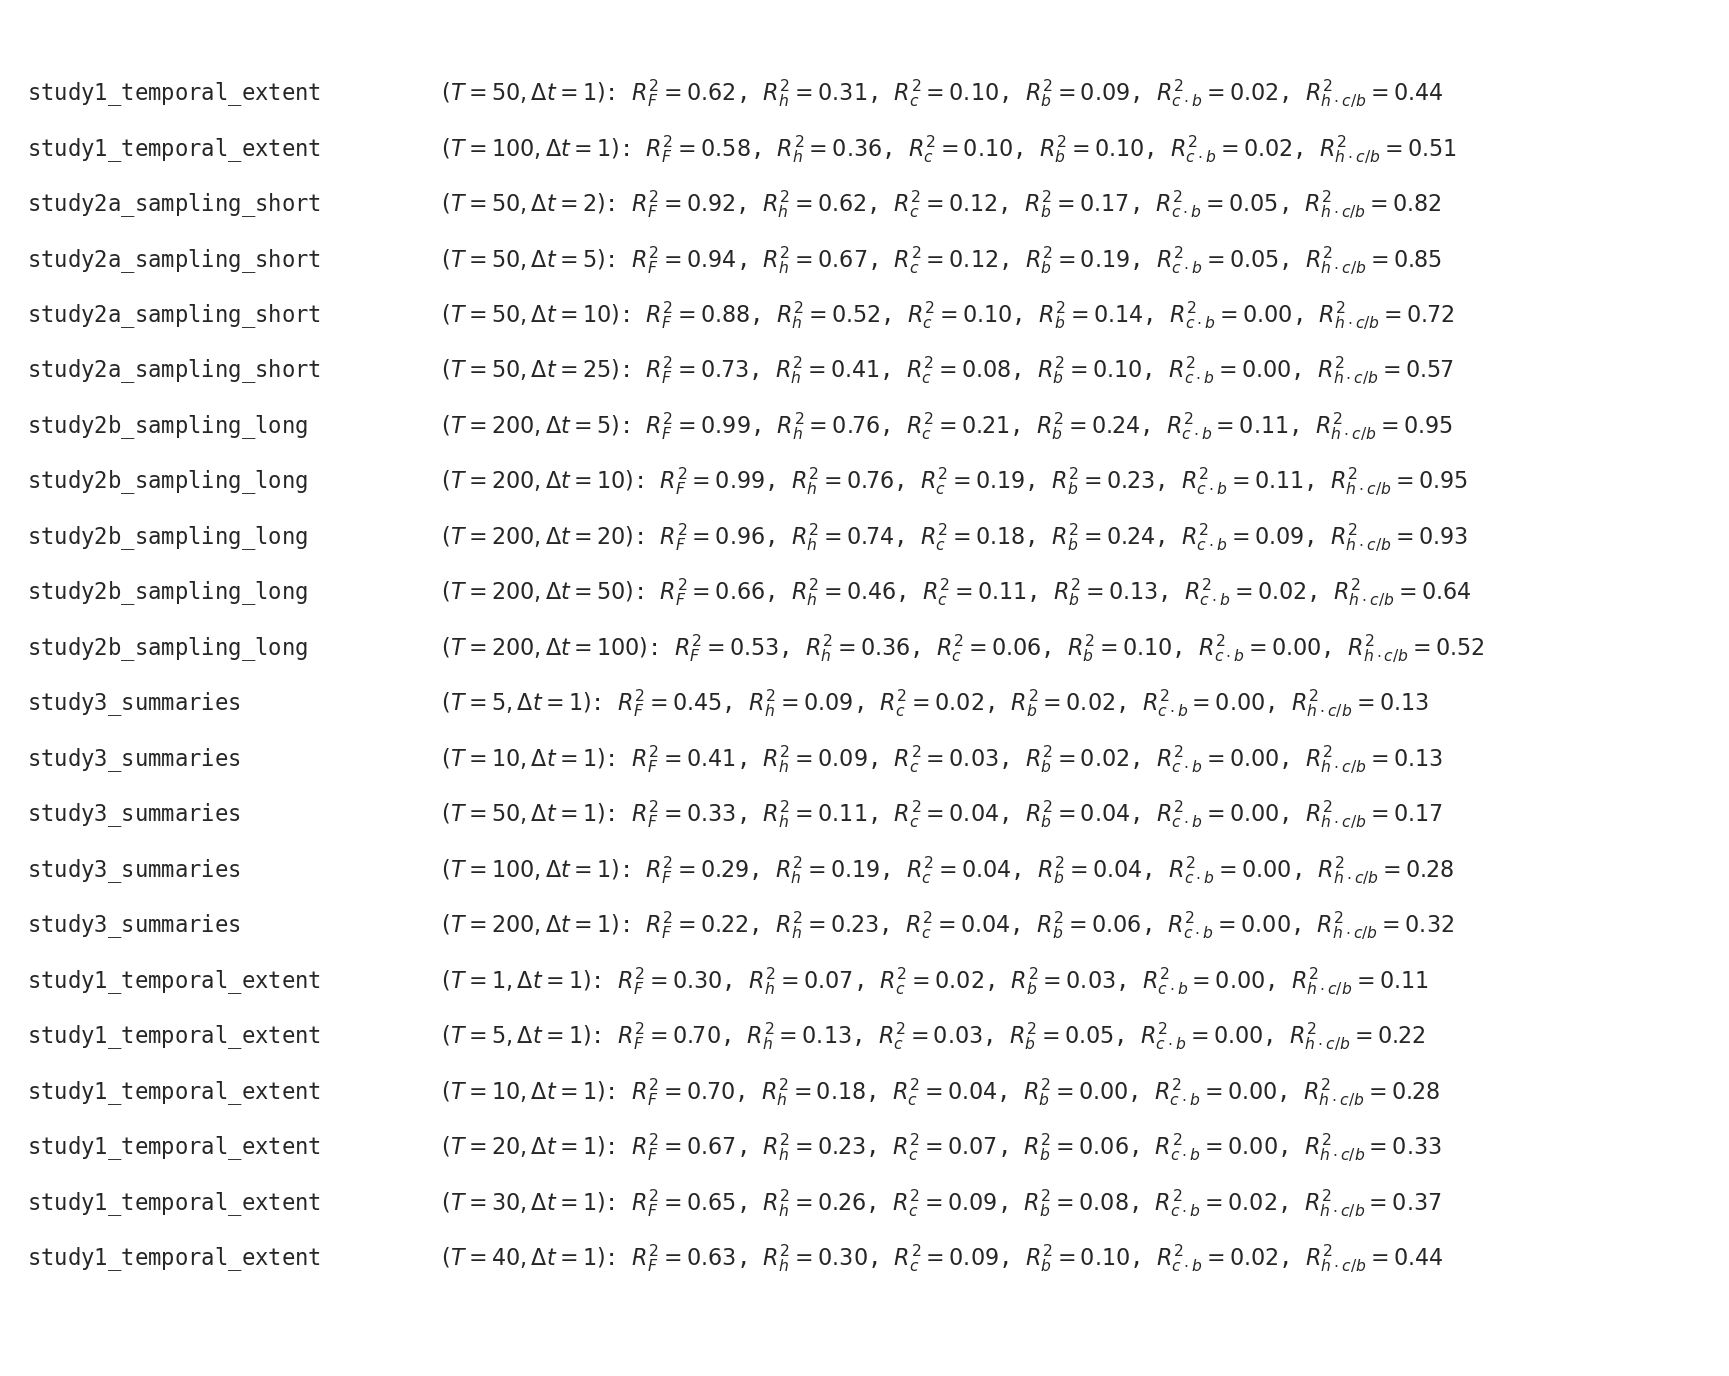

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from pathlib import Path

def compute_r2_for_parameters(models_dict, key):
    """
    Compute R² for base parameters (assuming order: F, h, c, b).
    
    Parameters:
    -----------
    models_dict : dict
        Dictionary containing model results
    key : str
        Key to access specific model results
        
    Returns:
    --------
    dict : Dictionary with R² values for each parameter
    """
    # Extract parameters
    params_true = models_dict[key]['params_true']
    params_gen = models_dict[key]['params_generated']
    
    # Calculate posterior means
    params_predicted = np.mean(params_gen, axis=1)
    
    # Compute R² for each parameter (assuming order: F, h, c, b)
    r2_values = {}
    param_names = ['ρ', 'σ', 'β', 'F']  # Adjust based on your parameter names
    # Or if your parameters are F, h, c, b:
    # param_names = ['F', 'h', 'c', 'b']
    
    for i, param_name in enumerate(param_names):
        if i < params_true.shape[1]:
            true_vals = params_true[:, i]
            pred_vals = params_predicted[:, i]
            r2_values[param_name] = r2_score(true_vals, pred_vals)
    
    return r2_values


def extract_experiment_params(key):
    """
    Extract T and dt from the key name.
    
    Parameters:
    -----------
    key : str
        Key name like 'study1_temporal_extent_T50_dt1_X'
        
    Returns:
    --------
    tuple : (T, dt) values
    """
    import re
    
    # Extract T value
    t_match = re.search(r'T(\d+)', key)
    T = int(t_match.group(1)) if t_match else None
    
    # Extract dt value
    dt_match = re.search(r'dt(\d+)', key)
    dt = int(dt_match.group(1)) if dt_match else None
    
    return T, dt


def compute_r2_all_parameters(models_dict, key, param_symbols=None):
    """
    Compute R² for all parameters including derived ones (h·c/b and c·b).
    
    Parameters:
    -----------
    models_dict : dict
        Dictionary containing model results
    key : str
        Key to access specific model results
    param_symbols : list, optional
        List of base parameter symbols
        
    Returns:
    --------
    dict : Dictionary with R² values for all parameters
    """
    if param_symbols is None:
        param_symbols = ['F', 'h', 'c', 'b']
    
    # Extract parameters
    params_true = models_dict[key]['params_true']
    params_gen = models_dict[key]['params_generated']
    params_predicted = np.mean(params_gen, axis=1)
    
    # Compute R² for base parameters
    r2_values = {}
    for i, param_symbol in enumerate(param_symbols):
        if i < params_true.shape[1]:
            true_vals = params_true[:, i]
            pred_vals = params_predicted[:, i]
            r2 = r2_score(true_vals, pred_vals)
            r2_values[param_symbol] = max(r2, 0)
    
    # Compute R² for derived parameter: c·b
    # Assuming order is F, h, c, b (indices 0, 1, 2, 3)
    if params_true.shape[1] >= 4:
        cb_true = params_true[:, 2] * params_true[:, 3]
        cb_samples = params_gen[:, :, 2] * params_gen[:, :, 3]
        cb_predicted = np.mean(cb_samples, axis=1)
        r2_cb = r2_score(cb_true, cb_predicted)
        r2_values['c·b'] = max(r2_cb, 0)
    
    # Compute R² for derived parameter: h·c/b
    if params_true.shape[1] >= 4:
        hcb_true = params_true[:, 1] * params_true[:, 2] / params_true[:, 3]
        hcb_samples = (params_gen[:, :, 1] * params_gen[:, :, 2] / 
                       params_gen[:, :, 3])
        hcb_predicted = np.mean(hcb_samples, axis=1)
        r2_hcb = r2_score(hcb_true, hcb_predicted)
        r2_values['h·c/b'] = max(r2_hcb, 0)
    
    return r2_values


def create_r2_summary_table_styled(models_dict, keys_to_analyze, 
                                   param_symbols=None,
                                   experiment=None,
                                   target_length=26,
                                   include_derived=True,
                                   data='test',
                                   output_dir='plots/tables'):
    """
    Create a styled R² summary table with custom parameter symbols.
    
    Parameters:
    -----------
    models_dict : dict
        Dictionary containing all model results
    keys_to_analyze : list
        List of study keys to analyze
    param_symbols : list, optional
        List of parameter symbols to use (e.g., ['ρ', 'σ', 'β', 'F'])
        If None, uses indices [0, 1, 2, 3] or ['F', 'h', 'c', 'b']
    experiment : str, optional
        Name for output files
    target_length : int
        Length to pad experiment case names
    include_derived : bool
        If True, include derived parameters h·c/b and c·b
    output_dir : str
        Directory to save the figure
    """
    import re
    
    # Default parameter symbols
    if param_symbols is None:
        param_symbols = ['F', 'h', 'c', 'b']
    
    # Collect all R² values
    results = []
    
    for key in keys_to_analyze:
        if key in models_dict:
            T, dt = extract_experiment_params(key)
            
            # Compute R² for all parameters (base + derived)
            if include_derived:
                r2_values = compute_r2_all_parameters(models_dict, key, param_symbols)
            else:
                # Just compute base parameters
                params_true = models_dict[key]['params_true']
                params_gen = models_dict[key]['params_generated']
                params_predicted = np.mean(params_gen, axis=1)
                
                r2_values = {}
                for i, param_symbol in enumerate(param_symbols):
                    if i < params_true.shape[1]:
                        true_vals = params_true[:, i]
                        pred_vals = params_predicted[:, i]
                        r2 = r2_score(true_vals, pred_vals)
                        r2_values[param_symbol] = max(r2, 0)
            
            results.append({
                'key': key,
                'T': T,
                'dt': dt,
                'r2_values': r2_values
            })
        else:
            print(f"⚠️  Warning: Key '{key}' not found in models_dict")
    
    # Create figure with appropriate size
    fig_height = max(len(results) * 0.6 + 0.5, 4)
    fig, ax = plt.subplots(figsize=(18, fig_height))  # Wider to accommodate more parameters
    ax.axis('off')
    
    # Create text lines
    y_position = 0.95
    y_step = 0.9 / len(results) if results else 0.1
    
    for result in results:
        experiment_case = re.sub(r'_T\d+_dt\d+.*$', '', result['key'])
        T = result['T']
        dt = result['dt']
        r2_vals = result['r2_values']
        
        # Format R² values with subscripts
        # Order: base parameters first, then derived parameters
        r2_strs = []
        
        # Add base parameters in order
        for param in param_symbols:
            if param in r2_vals:
                r2_strs.append(f"$R^2_{{{param}}} = {r2_vals[param]:.2f}$")
        
        # Add derived parameters if they exist
        if 'c·b' in r2_vals:
            r2_strs.append(f"$R^2_{{c \\cdot b}} = {r2_vals['c·b']:.2f}$")
        if 'h·c/b' in r2_vals:
            r2_strs.append(f"$R^2_{{h \\cdot c/b}} = {r2_vals['h·c/b']:.2f}$")
        
        r2_text = ", ".join(r2_strs)
        
        # Create line with proper LaTeX formatting
        # Option 2: More explicit control with separate padding
        experiment_part = experiment_case.ljust(target_length)
        params_part = f"$(T = {T:>4}, \\Delta t = {dt:>2})$:"
        params_part_padded = params_part.ljust(25)  # Adjust this number for desired spacing
        line = f"{experiment_part} {params_part_padded} {r2_text}"

        
        ax.text(0.01, y_position, line, transform=ax.transAxes,
                fontsize=16, verticalalignment='top', 
                family='monospace', fontstyle='normal')  # Changed to monospace for better alignment
        
        y_position -= y_step
    
    plt.tight_layout(pad=0.5)
    
    # Save figure
    Path(output_dir).mkdir(parents=True, exist_ok=True)
    output_path = Path(output_dir) / f'{experiment}_r2_summary_table_{data}_cc.png'
    plt.savefig(output_path, dpi=300, bbox_inches='tight', 
                facecolor='white', edgecolor='none')
    print(f"📊 R² summary table saved to: {output_path}")
    
    pdf_path = Path(output_dir) / f'{experiment}_r2_summary_table_{data}_cc.pdf'
    plt.savefig(pdf_path, bbox_inches='tight', facecolor='white')
    print(f"📄 PDF saved to: {pdf_path}")
    
    plt.show()
    
    return fig


# ============================================================
# Main execution
# ============================================================


fig1 = create_r2_summary_table_styled(
    models_dict_X, 
    keys_X,
    param_symbols=['F', 'h', 'c', 'b'],
    experiment='All_Cases_with_Derived_X',
    target_length=30,
    data = 'test_dp',
    include_derived=True,  # Set to True to include h·c/b and c·b
    output_dir='plots/tables'
)
# If you only want base parameters (no derived):
# fig2 = create_r2_summary_table_styled(
#     models_dict, 
#     keys_all,
#     param_symbols=['F', 'h', 'c', 'b'],
#     experiment='All_Cases_Base_Only',
#     target_length=30,
#     include_derived=False,
#     output_dir='plots/tables'
# )


📊 R² summary table saved to: plots/tables/All_Cases_with_Derived_X_r2_summary_table_test_dp.png
📄 PDF saved to: plots/tables/All_Cases_with_Derived_X_r2_summary_table_test_dp.pdf


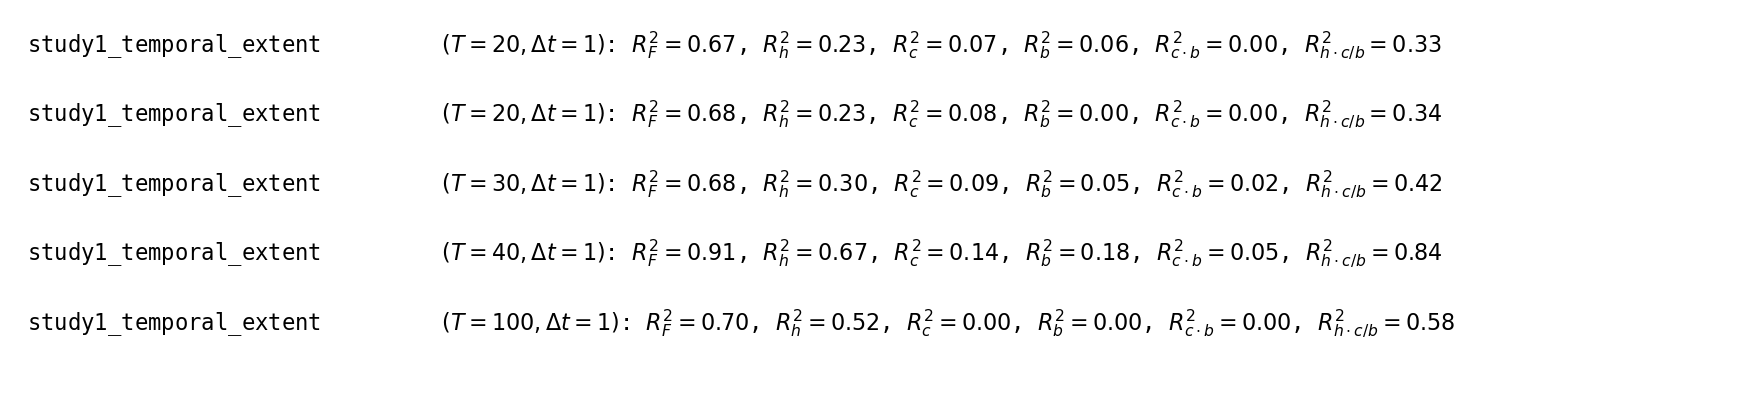

In [48]:
fig1 = create_r2_summary_table_styled(
    models_dict_X, 
    keys_X,#["study1_temporal_extent_T20_dt1_X_v3", "study1_temporal_extent_T20_dt1_X"],
    param_symbols=['F', 'h', 'c', 'b'],
    experiment='All_Cases_with_Derived_X',
    target_length=30,
    data = 'test_dp',
    include_derived=True,  # Set to True to include h·c/b and c·b
    output_dir='plots/tables'
)

In [29]:
# keys_Y = list(models_dict_Y.keys())
keys_Y.pop(6)
keys_Y[6]

'study1_temporal_extent_T100_dt1_Y'